In [1]:
import pypsa, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi":150, "savefig.dpi":300, "font.size":10,
                     "axes.grid":True, "grid.alpha":0.3})

RESULTS = Path("/Users/fowfloi/Documents/pypsa-earth/results")
OUT = Path("/Users/fowfloi/Documents/pypsa-earth/analysis")
OUT.mkdir(exist_ok=True)

EUR_TO_USD = 1.08               # ECB 2024 annual average EUR/USD, one EUR buys 1.08 USD
WACC_POINTS = [0.07, 0.09, 0.11, 0.1379, 0.18, 0.27]
NDC_POINTS  = [0.10, 0.1379, 0.27]
BASELINES = {
    "B2_split_hatton": "cap_exp_2030_split_wacc",
}
GAS_RUNS = {
    "gas_600": "nigeria_2030_wacc_1379_gas_600",
}
print("ready")

ready


In [2]:
def load_network(run_name):
    d = RESULTS / run_name / "networks"
    files = list(d.glob("*.nc"))
    if not files:
        return None
    return pypsa.Network(str(files[0]))

def summarise(n, wacc, constraint, label):
    gens = n.generators
    sto  = n.storage_units
    row = {"run": label, "wacc": wacc, "constraint": constraint}

    cap = gens.groupby("carrier").p_nom_opt.sum() / 1e3
    for c in ["solar","onwind","CCGT","OCGT","oil","biomass"]:
        row[f"cap_{c}_gw"] = float(cap.get(c, 0.0))
    bat = sto[sto.carrier == "battery"]
    hyd = sto[sto.carrier == "hydro"]
    row["cap_battery_gw"] = float(bat.p_nom_opt.sum()/1e3) if len(bat) else 0.0
    row["cap_hydro_gw"]   = float(hyd.p_nom.sum()/1e3)    if len(hyd) else 0.0

    gen = {}
    for c in gens.carrier.unique():
        cols = gens[gens.carrier == c].index
        if len(cols):
            gen[c] = float(n.generators_t.p[cols].sum().sum()/1e6)
    if len(hyd):
        gen["hydro"] = float(n.storage_units_t.p[hyd.index].clip(lower=0).sum().sum()/1e6)
    else:
        gen["hydro"] = 0.0
    for c in ["solar","onwind","CCGT","OCGT","hydro","oil","biomass"]:
        row[f"gen_{c}_twh"] = gen.get(c, 0.0)

    shed = gens[gens.carrier == "load shedding"]
    shed_twh = float(n.generators_t.p[shed.index].sum().sum()/1e6) if len(shed) else 0.0
    demand = float(n.loads_t.p_set.sum().sum()/1e6)
    row["demand_twh"] = demand
    row["served_twh"] = demand - shed_twh
    row["shed_twh"]   = shed_twh
    row["shed_pct"]   = 100*shed_twh/demand if demand else 0.0

    tot = sum(v for v in gen.values())
    row["gen_total_twh"] = tot
    if tot > 0:
        row["share_solar_pct"] = 100*row["gen_solar_twh"]/tot
        row["share_wind_pct"]  = 100*row["gen_onwind_twh"]/tot
        row["share_renew_pct"] = 100*(row["gen_solar_twh"]+row["gen_onwind_twh"]+row["gen_hydro_twh"])/tot
        row["share_gas_pct"]   = 100*(row["gen_CCGT_twh"]+row["gen_OCGT_twh"])/tot
    else:
        for k in ["share_solar_pct","share_wind_pct","share_renew_pct","share_gas_pct"]:
            row[k] = 0.0

    co2_map = n.carriers["co2_emissions"].reindex(gens.carrier.unique()).fillna(0.0)
    eff = gens.efficiency.replace(0, np.nan)
    fuel = n.generators_t.p[gens.index].div(eff, axis=1)
    row["emissions_mt_co2"] = float(fuel.mul(gens.carrier.map(co2_map), axis=1).sum().sum()/1e6)

    gen_capex = ((gens.p_nom_opt - gens.p_nom).clip(lower=0) * gens.capital_cost).sum()
    gen_opex  = (n.generators_t.p[gens.index] * gens.marginal_cost).sum().sum()
    lines_new = (n.lines.s_nom_opt - n.lines.s_nom).clip(lower=0)
    line_capex = (lines_new * n.lines.capital_cost).sum()
    storage_capex = (sto.capital_cost * sto.p_nom_opt).sum()
    total = gen_capex + gen_opex + line_capex

    row["gen_capex_bn_usd"]     = float(gen_capex*EUR_TO_USD/1e9)
    row["gen_opex_bn_usd"]      = float(gen_opex*EUR_TO_USD/1e9)
    row["line_capex_bn_usd"]    = float(line_capex*EUR_TO_USD/1e9)
    row["storage_capex_bn_usd"] = float(storage_capex*EUR_TO_USD/1e9)
    row["total_cost_bn_usd"]    = float(total*EUR_TO_USD/1e9)
    row["cost_per_mwh_usd"]     = float((total*EUR_TO_USD)/(row["served_twh"]*1e6)) if row["served_twh"] else np.nan
    row["line_capacity_gwkm"]   = float((n.lines.s_nom_opt * n.lines.length).sum()/1e3) if "s_nom_opt" in n.lines.columns else 0.0
    return row
print("functions ready")

functions ready


In [5]:
import pypsa, pandas as pd, numpy as np
from pathlib import Path

RESULTS = Path("/Users/fowfloi/Documents/pypsa-earth/results")
OUT = Path("/Users/fowfloi/Documents/pypsa-earth/analysis")
OUT.mkdir(exist_ok=True)
EUR_TO_USD = 1.3277   # keep consistent with the config; label as 2013 USD in the paper

def load_network(run_name):
    d = RESULTS / run_name / "networks"
    files = list(d.glob("*.nc"))
    return pypsa.Network(str(files[0])) if files else None

def summarise(n, wacc, constraint, label):
    gens = n.generators
    sto  = n.storage_units
    row = {"run": label, "wacc": wacc, "constraint": constraint}

    cap = gens.groupby("carrier").p_nom_opt.sum() / 1e3
    for c in ["solar","onwind","CCGT","OCGT"]:
        row[f"cap_{c}_gw"] = float(cap.get(c, 0.0))
    bat = sto[sto.carrier == "battery"]
    hyd = sto[sto.carrier == "hydro"]
    row["cap_battery_gw"] = float(bat.p_nom_opt.sum()/1e3) if len(bat) else 0.0
    row["cap_hydro_gw"]   = float(hyd.p_nom.sum()/1e3)    if len(hyd) else 0.0

    gen = {}
    for c in gens.carrier.unique():
        cols = gens[gens.carrier == c].index
        if len(cols):
            gen[c] = float(n.generators_t.p[cols].sum().sum()/1e6)
    gen["hydro"] = float(n.storage_units_t.p[hyd.index].clip(lower=0).sum().sum()/1e6) if len(hyd) else 0.0
    for c in ["solar","CCGT","OCGT","hydro"]:
        row[f"gen_{c}_twh"] = gen.get(c, 0.0)

    shed = gens[gens.carrier == "load shedding"]
    shed_twh = float(n.generators_t.p[shed.index].sum().sum()/1e6) if len(shed) else 0.0
    demand = float(n.loads_t.p_set.sum().sum()/1e6)
    row["demand_twh"] = demand
    row["served_twh"] = demand - shed_twh
    row["shed_twh"]   = shed_twh

    tot = sum(v for v in gen.values())
    row["gen_total_twh"] = tot
    if tot > 0:
        row["share_renew_pct"] = 100*(row["gen_solar_twh"]+row["gen_hydro_twh"])/tot
        row["share_gas_pct"]   = 100*(row["gen_CCGT_twh"]+row["gen_OCGT_twh"])/tot

    co2_map = n.carriers["co2_emissions"].reindex(gens.carrier.unique()).fillna(0.0)
    eff = gens.efficiency.replace(0, np.nan)
    row["emissions_mt_co2"] = float(
        n.generators_t.p[gens.index].div(eff, axis=1)
         .mul(gens.carrier.map(co2_map), axis=1).sum().sum()/1e6)

    gen_capex     = ((gens.p_nom_opt - gens.p_nom).clip(lower=0) * gens.capital_cost).sum()
    gen_opex      = (n.generators_t.p[gens.index] * gens.marginal_cost).sum().sum()
    line_capex    = ((n.lines.s_nom_opt - n.lines.s_nom).clip(lower=0) * n.lines.capital_cost).sum()
    storage_capex = (sto.capital_cost * sto.p_nom_opt).sum()
    total         = gen_capex + gen_opex + line_capex + storage_capex

    row["gen_capex_bn_usd"]     = float(gen_capex*EUR_TO_USD/1e9)
    row["gen_opex_bn_usd"]      = float(gen_opex*EUR_TO_USD/1e9)
    row["line_capex_bn_usd"]    = float(line_capex*EUR_TO_USD/1e9)
    row["storage_capex_bn_usd"] = float(storage_capex*EUR_TO_USD/1e9)
    row["total_cost_bn_usd"]    = float(total*EUR_TO_USD/1e9)
    row["cost_per_mwh_usd"]     = float((total*EUR_TO_USD)/(row["served_twh"]*1e6)) if row["served_twh"] else np.nan
    return row

RUNS = []
for w in [0.07, 0.09, 0.11, 0.1379, 0.18, 0.27]:
    RUNS.append((f"nigeria_2030_wacc_{int(round(w*10000)):04d}", w, "unconstrained"))
for w in [0.10, 0.1379, 0.27]:
    RUNS.append((f"nigeria_2030_wacc_{int(round(w*10000)):04d}_ndc", w, "ndc"))
RUNS.append(("nigeria_2030_wacc_1379_gas_600", 0.1379, "gas_600"))

rows = []
for rn, w, c in RUNS:
    n = load_network(rn)
    if n is None:
        print("MISSING:", rn); continue
    rows.append(summarise(n, w, c, rn))
    print(f"loaded {rn}: solar {rows[-1]['cap_solar_gw']:.2f} GW, "
          f"cost {rows[-1]['cost_per_mwh_usd']:.2f} USD/MWh")

df = pd.DataFrame(rows)
df.to_csv(OUT / "master_analysis.csv", index=False)
print(f"\nTotal runs: {len(df)}")

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_0700: solar 10.35 GW, cost 41.52 USD/MWh


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_0900: solar 9.20 GW, cost 43.33 USD/MWh
loaded nigeria_2030_wacc_1100: solar 8.69 GW, cost 45.07 USD/MWh


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


...

loaded nigeria_2030_wacc_2700: solar 4.90 GW, cost 57.46 USD/MWh
loaded nigeria_2030_wacc_1000_ndc: solar 31.56 GW, cost 56.38 USD/MWh


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1379_ndc: solar 31.64 GW, cost 71.09 USD/MWh
loaded nigeria_2030_wacc_2700_ndc: solar 30.91 GW, cost 122.57 USD/MWh


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1379_gas_600: solar 8.34 GW, cost 48.83 USD/MWh

Total runs: 10


In [6]:
cols = ["wacc","constraint",
        "cap_solar_gw","cap_OCGT_gw","cap_battery_gw",
        "gen_solar_twh","gen_hydro_twh","gen_CCGT_twh","gen_OCGT_twh",
        "share_renew_pct","share_gas_pct",
        "emissions_mt_co2",
        "gen_capex_bn_usd","gen_opex_bn_usd","storage_capex_bn_usd","line_capex_bn_usd",
        "total_cost_bn_usd","cost_per_mwh_usd"]

summary = df[cols].copy()
summary["wacc"] = (summary.wacc*100).round(2)
summary = summary.sort_values(["constraint","wacc"]).reset_index(drop=True)
summary = summary.round(2)
summary.to_csv(OUT / "result_summary.csv", index=False)
summary

,wacc,constraint,cap_solar_gw,cap_OCGT_gw,cap_battery_gw,gen_solar_twh,gen_hydro_twh,gen_CCGT_twh,gen_OCGT_twh,share_renew_pct,share_gas_pct,emissions_mt_co2,gen_capex_bn_usd,gen_opex_bn_usd,storage_capex_bn_usd,line_capex_bn_usd,total_cost_bn_usd,cost_per_mwh_usd
0,13.79,gas_600,8.34,28.43,1.63,11.33,8.45,9.26,49.14,25.27,74.62,26.89,2.80,0.64,0.35,0.01,3.80,48.83
1,10.00,ndc,31.56,9.31,10.97,50.52,8.41,8.57,12.21,73.86,26.05,8.82,2.29,0.24,1.86,0.00,4.39,56.38
2,13.79,ndc,31.64,10.14,10.39,50.58,8.37,8.21,12.47,73.95,25.94,8.82,3.04,0.25,2.25,0.00,5.54,71.09
3,27.00,ndc,30.91,8.74,8.80,48.93,8.27,13.31,8.86,71.95,27.89,8.82,5.76,0.32,3.46,0.00,9.54,122.57
4,7.00,unconstrained,10.35,27.11,2.08,14.17,8.45,9.26,46.37,28.89,71.04,25.55,2.48,0.48,0.28,0.00,3.24,41.52
5,9.00,unconstrained,9.20,27.95,1.73,12.43,8.45,9.26,48.06,26.68,73.24,26.37,2.59,0.50,0.27,0.01,3.38,43.33
6,11.00,unconstrained,8.69,28.25,1.64,11.81,8.45,9.26,48.67,25.88,74.02,26.66,2.68,0.52,0.30,0.01,3.51,45.07
7,13.79,unconstrained,8.17,28.56,1.63,11.04,8.45,9.26,49.43,24.90,74.99,27.03,2.80,0.53,0.35,0.01,3.70,47.49
8,18.00,unconstrained,7.38,29.15,1.63,9.85,8.45,9.26,50.60,23.39,76.49,27.60,2.96,0.56,0.44,0.02,3.97,51.03
9,27.00,unconstrained,4.90,31.59,1.62,6.11,8.45,9.26,54.31,18.61,81.23,29.39,3.18,0.63,0.64,0.02,4.47,57.46


In [8]:
unc = df[df.constraint=="unconstrained"].set_index(df[df.constraint=="unconstrained"].wacc.round(4))
ndc = df[df.constraint=="ndc"].sort_values("wacc")

prem_rows = []
for _, r in ndc.iterrows():
    if round(r.wacc,4) not in unc.index: continue
    u = unc.loc[round(r.wacc,4)]
    prem_rows.append({
        "wacc_pct": r.wacc*100,
        "unc_constrained_cost": round(u.cost_per_mwh_usd,2),
        "ndc_cost": round(r.cost_per_mwh_usd,2),
        "ndc_premium_usd_mwh": round(r.cost_per_mwh_usd - u.cost_per_mwh_usd,2),
        "ndc_solar_gw": round(r.cap_solar_gw,2),
        "unc_solar_gw": round(u.cap_solar_gw,2),
        "ndc_emissions": round(r.emissions_mt_co2,2),
        "unc_emissions": round(u.emissions_mt_co2,2),
    })
prem = pd.DataFrame(prem_rows)
prem.to_csv(OUT / "ndc_premium.csv", index=False)
prem

,wacc_pct,unc_constrained_cost,ndc_cost,ndc_premium_usd_mwh,ndc_solar_gw,unc_solar_gw,ndc_emissions,unc_emissions
0,13.79,47.49,71.09,23.60,31.64,8.17,8.82,27.03
1,27.00,57.46,122.57,65.11,30.91,4.90,8.82,29.39


In [ ]:
import pypsa

for wacc in ["0700", "2700"]:
    n = pypsa.Network(f"results/nigeria_2030_wacc_{wacc}/networks/elec_s_10_ec_lcopt_1h.nc")
    solar = n.generators[n.generators.carrier == "solar"].p_nom_opt.sum() / 1e3
    ccgt = n.generators[n.generators.carrier == "CCGT"].p_nom_opt.sum() / 1e3
    ocgt = n.generators[n.generators.carrier == "OCGT"].p_nom_opt.sum() / 1e3
    bat  = n.storage_units[n.storage_units.carrier == "battery"].p_nom_opt.sum() / 1e3
    print(f"WACC {int(wacc)/100:.0f}%: solar={solar:.1f} GW, CCGT={ccgt:.1f} GW, OCGT={ocgt:.1f} GW, battery={bat:.1f} GW")

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


WACC 7%: solar=5.7 GW, CCGT=3.4 GW, OCGT=8.7 GW, battery=1.7 GW
WACC 27%: solar=4.8 GW, CCGT=3.4 GW, OCGT=8.7 GW, battery=1.8 GW


In [ ]:
n = load_network("nigeria_2030_wacc_1379_ndc")
b = n.storage_units[n.storage_units.carrier=="battery"]
print("battery p_nom_opt:", b.p_nom_opt.sum()/1000, "GW")
print("battery capital_cost:", b.capital_cost.unique())
print("storage capex (EUR):", (b.capital_cost * b.p_nom_opt).sum())
print("storage capex (USD bn):", (b.capital_cost * b.p_nom_opt).sum()*EUR_TO_USD/1e9)

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


battery p_nom_opt: 10.394967838257953 GW
battery capital_cost: [163013.90328616]
storage capex (EUR): 1694524281.848514
storage capex (USD bn): 1.8300862243963953


In [ ]:
unc = sweep[sweep.constraint=="unconstrained"].sort_values("wacc").reset_index(drop=True)

low  = unc.iloc[0]   # 7%
high = unc.iloc[-1]  # 27%

solar_drop_gw  = low.cap_solar_gw - high.cap_solar_gw
solar_drop_pct = 100 * solar_drop_gw / low.cap_solar_gw

# Is the response monotone and smooth? Check first differences.
d_solar = unc.cap_solar_gw.diff().dropna()
d_cost  = unc.cost_per_mwh_usd.diff().dropna()

print(f"Solar at 7% WACC:   {low.cap_solar_gw:.2f} GW")
print(f"Solar at 27% WACC:  {high.cap_solar_gw:.2f} GW")
print(f"Absolute fall:      {solar_drop_gw:.2f} GW  ({solar_drop_pct:.1f}%)")
print(f"Monotone decreasing: {all(d_solar < 0)}")
print(f"Largest single-step drop: {abs(d_solar).max():.2f} GW "
      f"({100*abs(d_solar).max()/low.cap_solar_gw:.1f}% of base)")
print(f"Cost at 7% WACC:    {low.cost_per_mwh_usd:.2f} USD/MWh")
print(f"Cost at 27% WACC:   {high.cost_per_mwh_usd:.2f} USD/MWh")
print(f"Cost rise:          {high.cost_per_mwh_usd-low.cost_per_mwh_usd:.2f} USD/MWh "
      f"({100*(high.cost_per_mwh_usd-low.cost_per_mwh_usd)/low.cost_per_mwh_usd:.1f}%)")


Solar at 7% WACC:   10.35 GW
Solar at 27% WACC:  4.90 GW
Absolute fall:      5.45 GW  (52.7%)
Monotone decreasing: True
Largest single-step drop: 2.48 GW (24.0% of base)
Cost at 7% WACC:    30.82 USD/MWh
Cost at 27% WACC:   40.10 USD/MWh
Cost rise:          9.28 USD/MWh (30.1%)


In [ ]:
base = df[(df.constraint=="unconstrained") & (df.wacc.round(4)==0.1379)].iloc[0]
gas6 = df[df.constraint=="gas_600"].iloc[0]

print("At 13.79% WACC:")
print(f"  gas @ $3.39: solar {base.cap_solar_gw:.2f} GW, "
      f"cost {base.cost_per_mwh_usd:.2f} USD/MWh, "
      f"emissions {base.emissions_mt_co2:.2f} Mt")
print(f"  gas @ $6.00: solar {gas6.cap_solar_gw:.2f} GW, "
      f"cost {gas6.cost_per_mwh_usd:.2f} USD/MWh, "
      f"emissions {gas6.emissions_mt_co2:.2f} Mt")

gas_effect_pct  = 100*(gas6.cap_solar_gw - base.cap_solar_gw)/base.cap_solar_gw
wacc_effect_pct = solar_drop_pct   # from RQ1 cell

print(f"\nGas-price effect on solar: {gas_effect_pct:+.1f}%")
print(f"WACC effect on solar:      {wacc_effect_pct:+.1f}%")
print(f"Ratio (WACC / gas price):  {abs(wacc_effect_pct/gas_effect_pct):.1f}x")

At 13.79% WACC:
  gas @ $3.39: solar 8.17 GW, cost 34.95 USD/MWh, emissions 27.03 Mt
  gas @ $6.00: solar 8.34 GW, cost 36.04 USD/MWh, emissions 26.89 Mt

Gas-price effect on solar: +2.0%
WACC effect on solar:      +52.7%
Ratio (WACC / gas price):  25.7x


In [ ]:
def annuity(r, L):
    return r/(1-(1+r)**-L)

cap_solar = 600_000    # EUR/MW from costs.csv
L_solar   = 25
cap_ccgt  = 800_000    # EUR/MW
L_ccgt    = 30

for r_sol, r_gas, note in [
    (0.1379, 0.1468, "your central case"),
    (0.1379, 0.1379, "same rate for both"),
    (0.0710, 0.1468, "low renewable rate"),
]:
    a_s = annuity(r_sol, L_solar) * cap_solar / 1000
    a_g = annuity(r_gas, L_ccgt)  * cap_ccgt  / 1000
    print(f"{note:25s}  solar WACC {r_sol*100:5.2f}% -> {a_s:7.1f} EUR/kW/yr   "
          f"gas WACC {r_gas*100:5.2f}% -> {a_g:7.1f} EUR/kW/yr")

your central case          solar WACC 13.79% ->    86.1 EUR/kW/yr   gas WACC 14.68% ->   119.4 EUR/kW/yr
same rate for both         solar WACC 13.79% ->    86.1 EUR/kW/yr   gas WACC 13.79% ->   112.7 EUR/kW/yr
low renewable rate         solar WACC  7.10% ->    52.0 EUR/kW/yr   gas WACC 14.68% ->   119.4 EUR/kW/yr


In [17]:
# LCOE for solar and CCGT at each WACC point, using the same parameters as the notebook
def lcoe(capex_usd_kw, fom_pct, vom_usd_mwh, fuel_usd_mwh, eff, cf, wacc, life):
    crf = wacc * (1+wacc)**life / ((1+wacc)**life - 1)
    annual_capex = capex_usd_kw * crf * 1000
    return annual_capex/(cf*8760) + vom_usd_mwh + fuel_usd_mwh/eff

params = {
    "Solar": {"capex":800,"cf":0.20,"eff":1.0,"vom":0,"fuel":0,"fom":0.01,"life":25},
    "CCGT":  {"capex":850,"cf":0.55,"eff":0.58,"vom":4,"fuel":0.748,"fom":0.025,"life":30},
}

lcoe_rows = []
for w in unc.wacc.values:
    s = lcoe(params["Solar"]["capex"],params["Solar"]["fom"],params["Solar"]["vom"],
             params["Solar"]["fuel"],params["Solar"]["eff"],params["Solar"]["cf"],w,params["Solar"]["life"])
    g = lcoe(params["CCGT"]["capex"],params["CCGT"]["fom"],params["CCGT"]["vom"],
             params["CCGT"]["fuel"],params["CCGT"]["eff"],params["CCGT"]["cf"],w,params["CCGT"]["life"])
    lcoe_rows.append({"wacc_pct":w*100, "solar_lcoe":s, "ccgt_lcoe":g, "solar_minus_ccgt":s-g})
lcoe_tbl = pd.DataFrame(lcoe_rows)
print(lcoe_tbl.round(2).to_string(index=False))

# LCOE crossover: interpolate where solar_minus_ccgt changes sign
s = lcoe_tbl.solar_minus_ccgt.values
x = lcoe_tbl.wacc_pct.values
cross_idx = np.where(np.diff(np.sign(s)))[0]
if len(cross_idx):
    i = cross_idx[0]
    x0,x1 = x[i],x[i+1]; s0,s1 = s[i],s[i+1]
    lcoe_cross = x0 - s0*(x1-x0)/(s1-s0)
    print(f"\nLCOE crossover (solar vs CCGT): {lcoe_cross:.2f}% WACC")
else:
    print("\nNo LCOE crossover in range")

# System crossover: where solar capacity overtakes gas capacity (CCGT + OCGT)
unc2 = unc.copy()
unc2["gas_cap"] = unc2.cap_CCGT_gw + unc2.cap_OCGT_gw
unc2["solar_minus_gas"] = unc2.cap_solar_gw - unc2.gas_cap
print("\nSolar capacity minus gas capacity, by WACC:")
print(unc2[["wacc","cap_solar_gw","gas_cap","solar_minus_gas"]].round(2).to_string(index=False))

 wacc_pct  solar_lcoe  ccgt_lcoe  solar_minus_ccgt
     7.00       39.18      19.51             19.68
     9.00       46.49      22.46             24.02
    11.00       54.22      25.58             28.64
    13.79       65.56      30.13             35.43
    18.00       83.52      37.27             46.26
    27.00      123.60      52.96             70.64

No LCOE crossover in range

Solar capacity minus gas capacity, by WACC:
 wacc  cap_solar_gw  gas_cap  solar_minus_gas
 0.07         10.35    30.56           -20.21
 0.09          9.20    31.40           -22.20
 0.11          8.69    31.69           -23.00
 0.14          8.17    32.00           -23.83
 0.18          7.38    32.59           -25.21
 0.27          4.90    35.04           -30.14


In [ ]:
observed_wacc = 27.0
hatton_wacc   = 13.79
gap = observed_wacc - hatton_wacc

instrument_classes = {
    "Revenue de-risking (PPA, guaranteed offtake)": 3,
    "Rating de-risking (partial credit guarantee)":  5,
    "Blended finance (concessional + commercial)":   6,
}

print(f"Gap from observed {observed_wacc:.2f}% to Hatton {hatton_wacc:.2f}%: {gap:.2f} pp\n")
remaining = gap
for name, eff in instrument_classes.items():
    applied = min(eff, remaining)
    remaining -= applied
    print(f"  {name:50s}  -{applied:.0f} pp   remaining {remaining:.1f} pp")
print(f"\nStacked effect: {gap-remaining:.1f} pp, residual gap: {remaining:.1f} pp")

# Alternative framing: what WACC must be reached to hit key outcomes
for target, label in [(0.20, "solar > 5 GW"), (0.14, "solar > 8 GW"), (0.10, "solar > 10 GW")]:
    sub = unc[unc.wacc <= target]
    if len(sub):
        gw = sub.iloc[-1].cap_solar_gw
        print(f"To reach {label}: WACC must be <= {target*100:.0f}% (solar {gw:.2f} GW)")

Gap from observed 27.00% to Hatton 13.79%: 13.21 pp

  Revenue de-risking (PPA, guaranteed offtake)        -3 pp   remaining 10.2 pp
  Rating de-risking (partial credit guarantee)        -5 pp   remaining 5.2 pp
  Blended finance (concessional + commercial)         -5 pp   remaining 0.0 pp

Stacked effect: 13.2 pp, residual gap: 0.0 pp
To reach solar > 5 GW: WACC must be <= 20% (solar 7.38 GW)
To reach solar > 8 GW: WACC must be <= 14% (solar 8.17 GW)
To reach solar > 10 GW: WACC must be <= 10% (solar 9.20 GW)


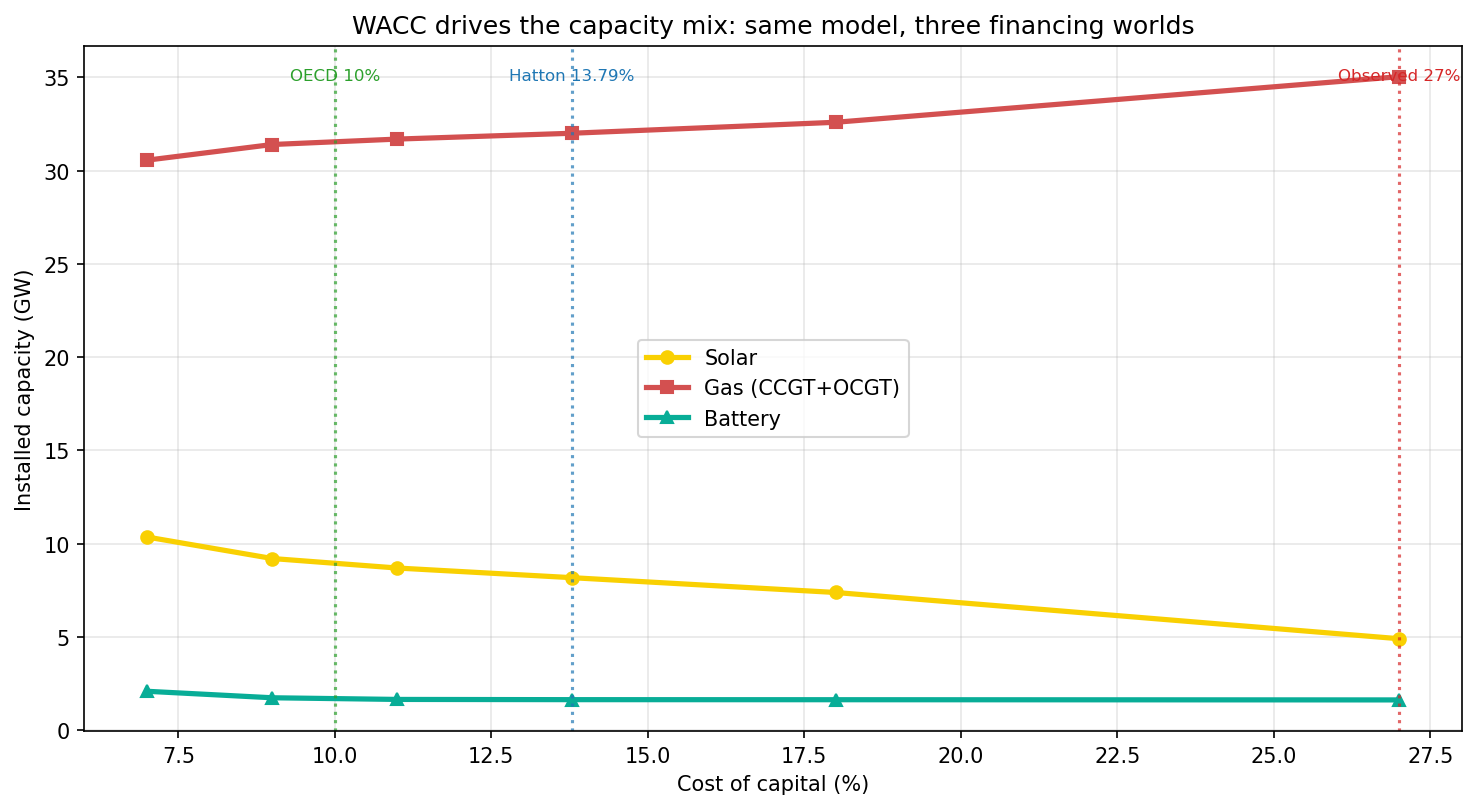

In [ ]:
fig, ax = plt.subplots(figsize=(10,5.5))
x = unc.wacc*100

ax.plot(x, unc.cap_solar_gw, "o-", color="#f9d002", lw=2.5, label="Solar")
ax.plot(x, unc.cap_CCGT_gw + unc.cap_OCGT_gw, "s-", color="#d35050", lw=2.5, label="Gas (CCGT+OCGT)")
ax.plot(x, unc.cap_battery_gw, "^-", color="#08ad97", lw=2.5, label="Battery")

for val, label, col in [
    (10.0, "OECD 10%", "#2ca02c"),
    (13.79,"Hatton 13.79%", "#1f77b4"),
    (27.0, "Observed 27%", "#d62728"),
]:
    ax.axvline(val, color=col, ls=":", alpha=0.7, lw=1.5)
    ax.text(val, ax.get_ylim()[1]*0.95, label, fontsize=8, color=col, ha="center")

ax.set_xlabel("Cost of capital (%)")
ax.set_ylabel("Installed capacity (GW)")
ax.set_title("WACC drives the capacity mix: same model, three financing worlds")
ax.legend()
plt.tight_layout(); plt.savefig(OUT/"rq1_cap_labelled.png", bbox_inches="tight"); plt.show()

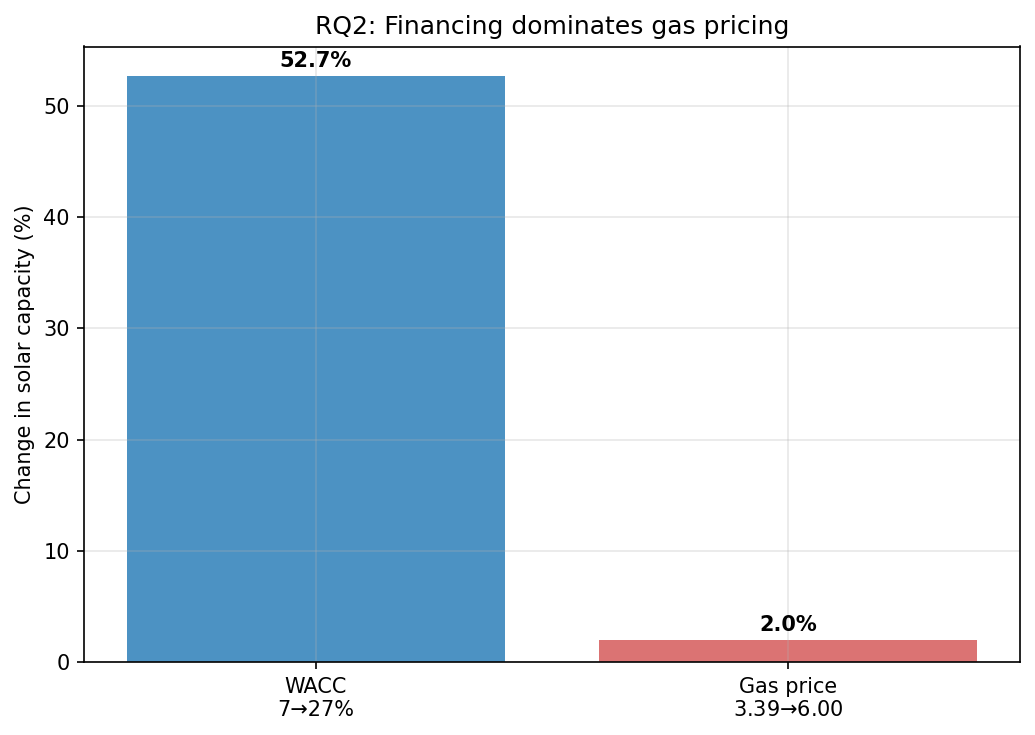

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(["WACC\n7→27%", "Gas price\n$3.39→$6.00"],
              [52.7, 2.0], color=["#1f77b4","#d35050"], alpha=0.8)
ax.set_ylabel("Change in solar capacity (%)")
ax.set_title("RQ2: Financing dominates gas pricing")
for b, v in zip(bars, [52.7, 2.0]):
    ax.text(b.get_x()+b.get_width()/2, v+0.8, f"{v:.1f}%", ha="center", fontweight="bold")
plt.tight_layout(); plt.savefig(OUT/"rq2_levers.png", bbox_inches="tight"); plt.show()

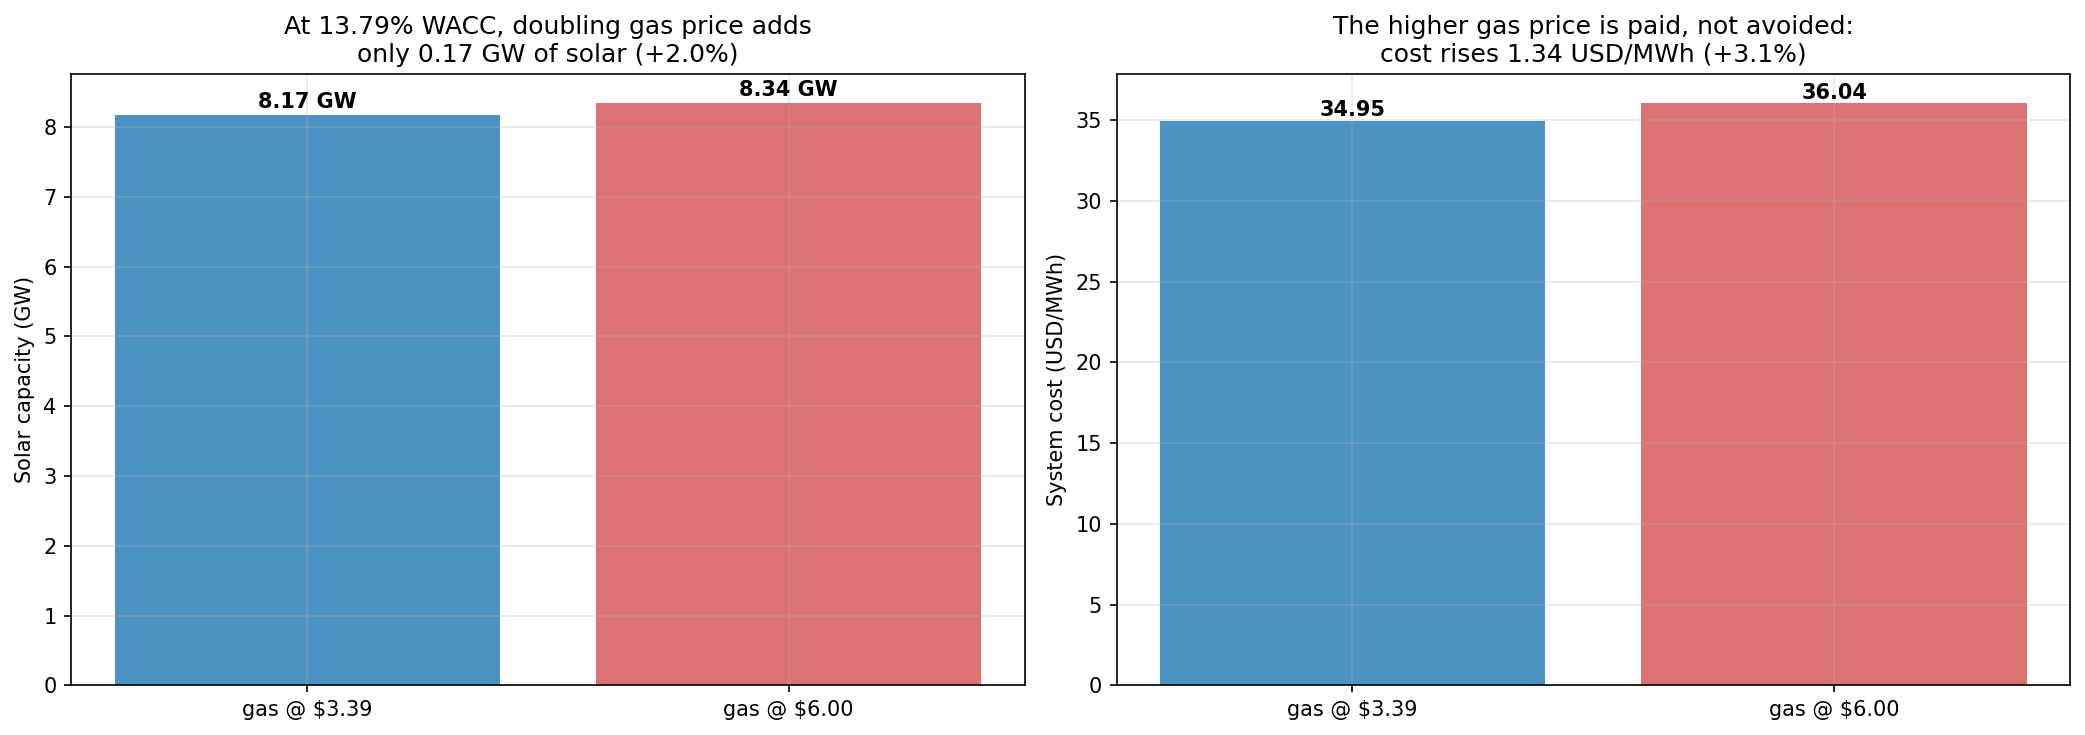

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Left: solar under both gas prices across WACC
# (you only have gas_600 at 13.79%, so this is a bar chart)
labels = ["gas @ $3.39", "gas @ $6.00"]
solar_vals = [base.cap_solar_gw, gas6.cap_solar_gw]
cost_vals  = [base.cost_per_mwh_usd, gas6.cost_per_mwh_usd]

ax = axes[0]
bars = ax.bar(labels, solar_vals, color=["#1f77b4","#d35050"], alpha=0.8)
for b, v in zip(bars, solar_vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.1, f"{v:.2f} GW", ha="center", fontweight="bold")
ax.set_ylabel("Solar capacity (GW)")
ax.set_title("At 13.79% WACC, doubling gas price adds\nonly 0.17 GW of solar (+2.0%)")

ax = axes[1]
bars = ax.bar(labels, cost_vals, color=["#1f77b4","#d35050"], alpha=0.8)
for b, v in zip(bars, cost_vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.3, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylabel("System cost (USD/MWh)")
ax.set_title("The higher gas price is paid, not avoided:\ncost rises 1.34 USD/MWh (+3.1%)")

plt.tight_layout(); plt.savefig(OUT/"rq2_gas_two_panel.png", bbox_inches="tight"); plt.show()

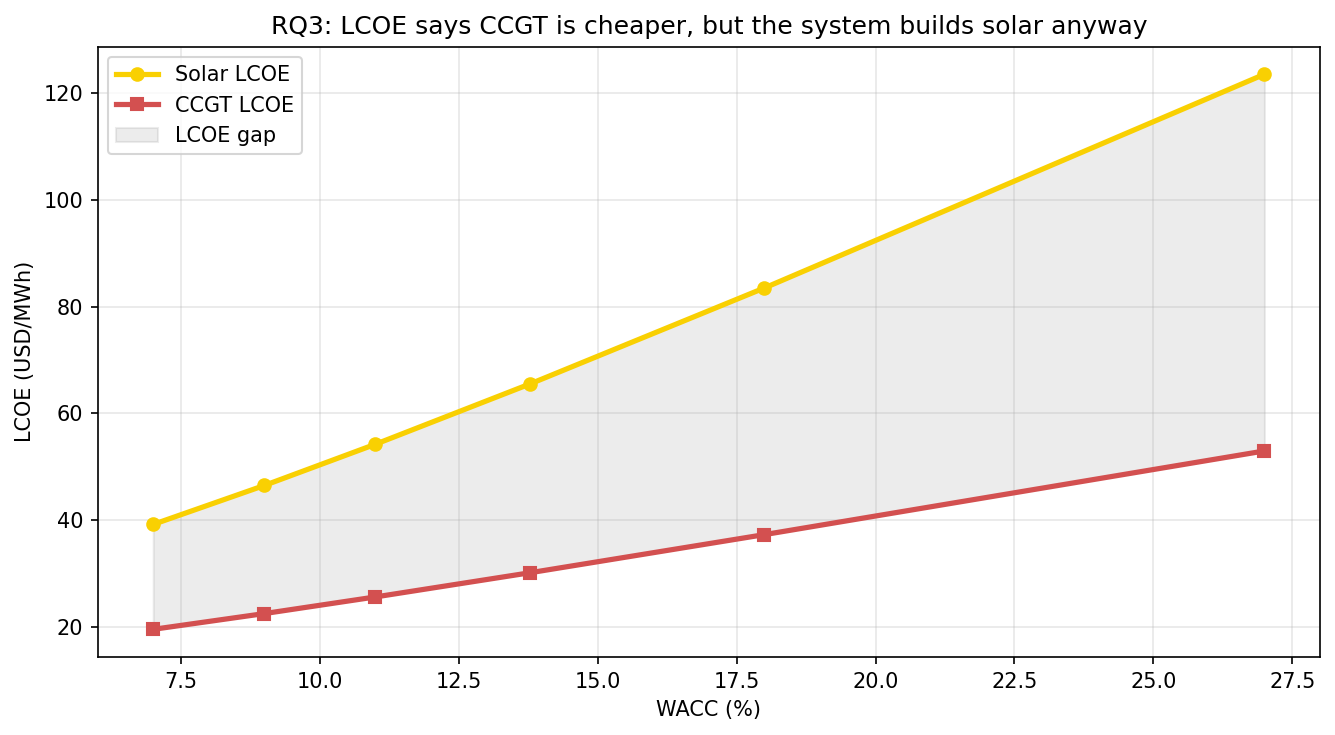

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(lcoe_tbl.wacc_pct, lcoe_tbl.solar_lcoe, "o-", color="#f9d002", lw=2.5, label="Solar LCOE")
ax.plot(lcoe_tbl.wacc_pct, lcoe_tbl.ccgt_lcoe, "s-", color="#d35050", lw=2.5, label="CCGT LCOE")
ax.fill_between(lcoe_tbl.wacc_pct, lcoe_tbl.ccgt_lcoe, lcoe_tbl.solar_lcoe,
                alpha=0.15, color="grey", label="LCOE gap")
ax.set_xlabel("WACC (%)"); ax.set_ylabel("LCOE (USD/MWh)")
ax.set_title("RQ3: LCOE says CCGT is cheaper, but the system builds solar anyway")
ax.legend()
plt.tight_layout(); plt.savefig(OUT/"rq3_lcoe_gap.png", bbox_inches="tight"); plt.show()

In [ ]:
ndc = sweep[sweep.constraint=="ndc"].sort_values("wacc").reset_index(drop=True)
unc_matched = unc.set_index(unc.wacc.round(4))

premium_rows = []
for _, r in ndc.iterrows():
    key = round(r.wacc, 4)
    if key not in unc_matched.index:
        continue
    u = unc_matched.loc[key]
    premium_rows.append({
        "wacc_pct": r.wacc*100,
        "ndc_cost": r.cost_per_mwh_usd,
        "unc_cost": u.cost_per_mwh_usd,
        "premium_usd_mwh": r.cost_per_mwh_usd - u.cost_per_mwh_usd,
    })
prem = pd.DataFrame(premium_rows)
print(prem.round(2).to_string(index=False))

 wacc_pct  ndc_cost  unc_cost  premium_usd_mwh
    13.79     34.34     34.95            -0.61
    27.00     63.52     40.10            23.42


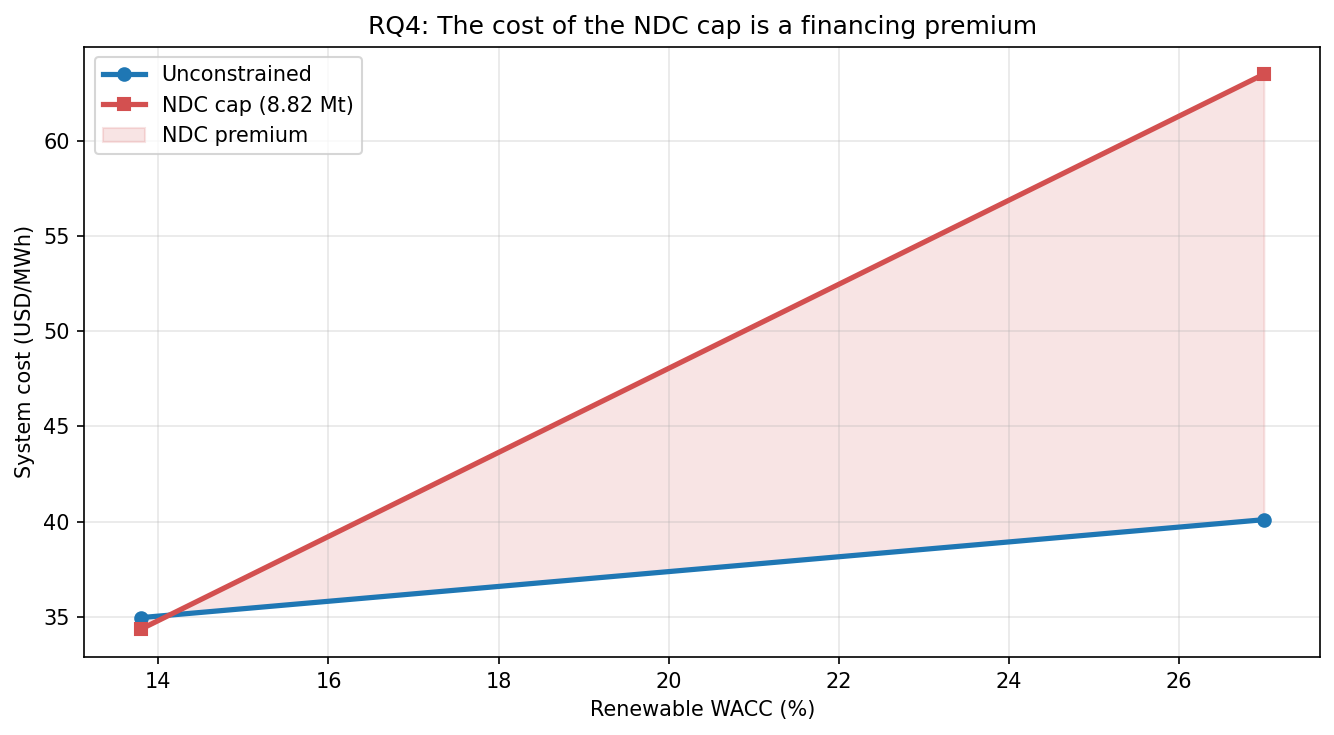

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(prem.wacc_pct, prem.unc_cost, "o-", color="#1f77b4", lw=2.5, label="Unconstrained")
ax.plot(prem.wacc_pct, prem.ndc_cost, "s-", color="#d35050", lw=2.5, label="NDC cap (8.82 Mt)")
ax.fill_between(prem.wacc_pct, prem.unc_cost, prem.ndc_cost, alpha=0.15, color="#d35050",
                label="NDC premium")
ax.set_xlabel("Renewable WACC (%)"); ax.set_ylabel("System cost (USD/MWh)")
ax.set_title("RQ4: The cost of the NDC cap is a financing premium")
ax.legend()
plt.tight_layout(); plt.savefig(OUT/"rq4_ndc_cost.png", bbox_inches="tight"); plt.show()

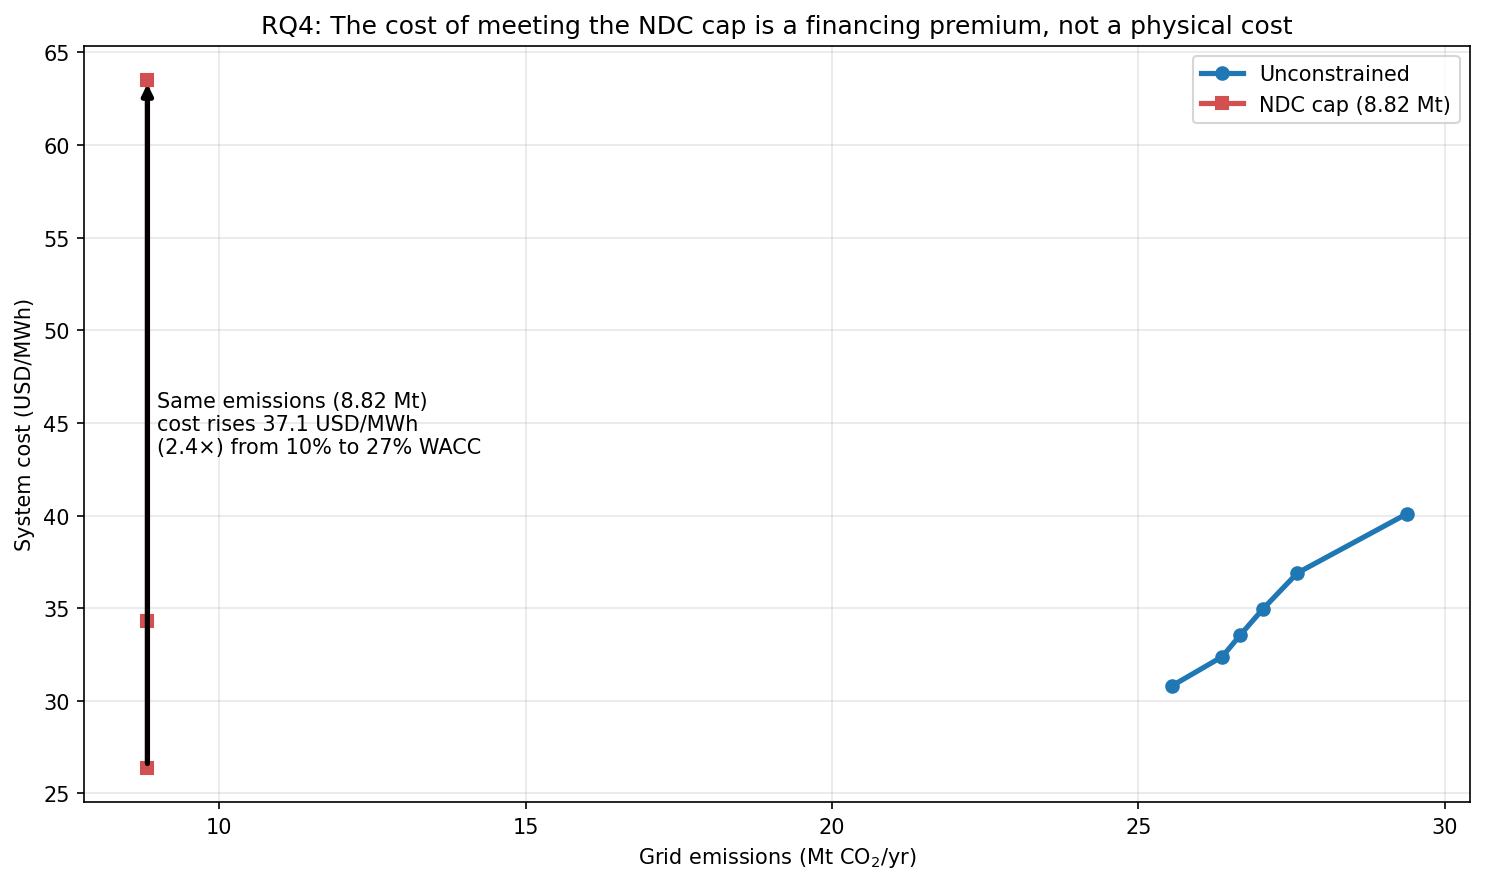

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))

# Cost vs emissions for both scenarios
ax.plot(unc.emissions_mt_co2, unc.cost_per_mwh_usd, "o-", color="#1f77b4",
        lw=2.5, label="Unconstrained")
ax.plot(ndc.emissions_mt_co2, ndc.cost_per_mwh_usd, "s-", color="#d35050",
        lw=2.5, label="NDC cap (8.82 Mt)")

# The arrow: same emissions, higher cost as WACC rises
e_ndc = ndc.emissions_mt_co2.iloc[0]
c_low  = ndc.cost_per_mwh_usd.iloc[0]   # 10% WACC
c_high = ndc.cost_per_mwh_usd.iloc[-1]  # 27% WACC

ax.annotate("",
            xy=(e_ndc, c_high),
            xytext=(e_ndc, c_low),
            arrowprops=dict(arrowstyle="-|>", color="black", lw=2.5))
ax.text(e_ndc + 0.15, (c_low + c_high)/2,
        f"Same emissions (8.82 Mt)\ncost rises {c_high - c_low:.1f} USD/MWh\n"
        f"({c_high/c_low:.1f}×) from 10% to 27% WACC",
        fontsize=10, va="center")

ax.set_xlabel("Grid emissions (Mt CO$_2$/yr)")
ax.set_ylabel("System cost (USD/MWh)")
ax.set_title("RQ4: The cost of meeting the NDC cap is a financing premium, not a physical cost")
ax.legend()
plt.tight_layout(); plt.savefig(OUT/"rq4_arrow.png", bbox_inches="tight"); plt.show()

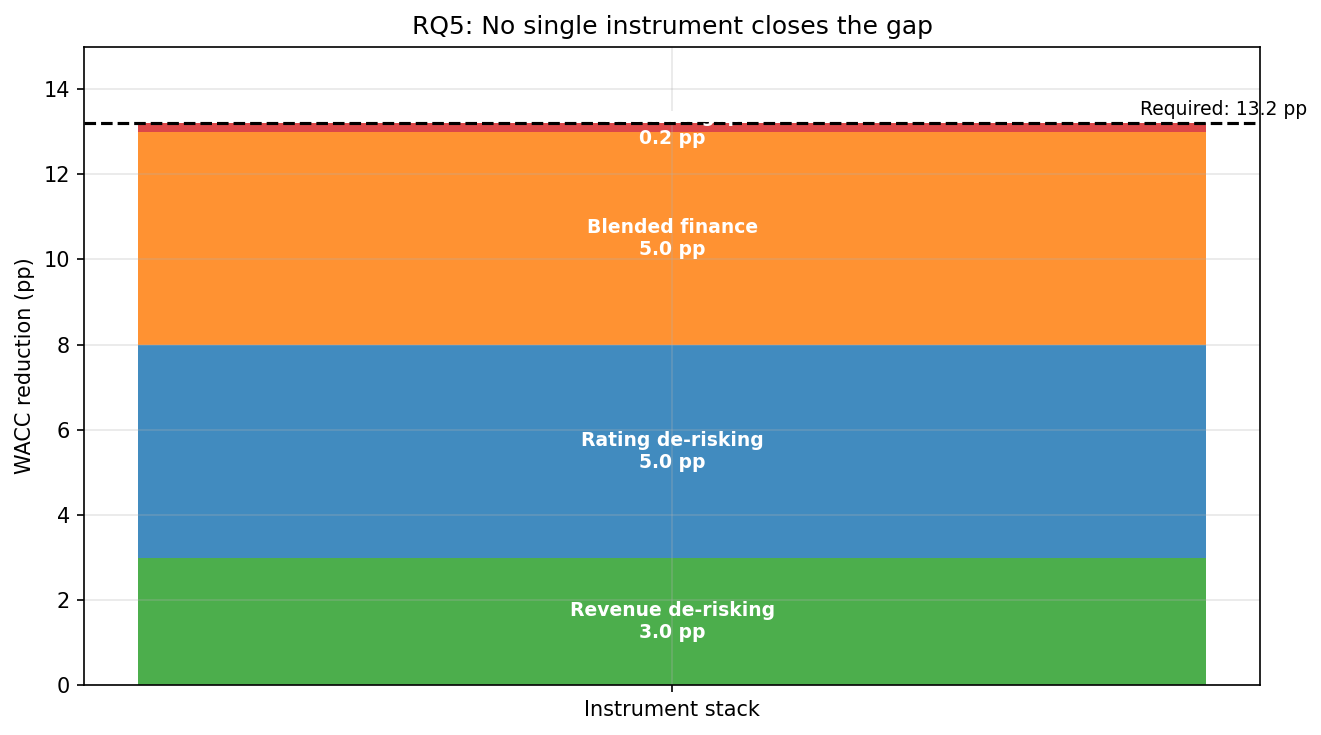

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
labels = ["Revenue\nde-risking", "Rating\nde-risking", "Blended\nfinance", "Residual\ngap"]
values = [3, 5, 5, 0.2]
colors = ["#2ca02c","#1f77b4","#ff7f0e","#d62728"]
bottom = 0
for lab, v, c in zip(labels, values, colors):
    ax.bar("Instrument stack", v, bottom=bottom, color=c, label=lab, alpha=0.85)
    ax.text(0, bottom+v/2, f"{lab.replace(chr(10),' ')}\n{v:.1f} pp",
            ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    bottom += v
ax.axhline(13.21, color="black", ls="--", lw=1.5)
ax.text(0.35, 13.4, "Required: 13.2 pp", fontsize=9)
ax.set_ylabel("WACC reduction (pp)")
ax.set_title("RQ5: No single instrument closes the gap")
ax.set_ylim(0, 15)
plt.tight_layout(); plt.savefig(OUT/"rq5_policy.png", bbox_inches="tight"); plt.show()

In [ ]:
# LCOE gap is fixed per WACC. What changes with VOLL is the system value.
# Approximate system value per MWh of solar = VOLL * (fraction of hours solar reduces shedding)
# Use the actual model output to derive this at 13.79% WACC.

base = load_network("nigeria_2030_wacc_1379")
solar_gen_twh = base.generators[base.generators.carrier=="solar"].pipe(
    lambda s: base.generators_t.p[s.index].sum().sum()/1e6)
shed_twh = base.generators[base.generators.carrier=="load shedding"].pipe(
    lambda s: base.generators_t.p[s.index].sum().sum()/1e6)

print(f"Solar generation at 13.79%: {solar_gen_twh:.2f} TWh")
print(f"Load shedding at 13.79%: {shed_twh:.2f} TWh")
print(f"VOLL assumed: 1000 EUR/MWh")
print(f"Upper bound value of avoided shedding from solar: {shed_twh*1000/1e9:.2f} bn EUR")

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


Solar generation at 13.79%: 11.04 TWh
Load shedding at 13.79%: 0.08 TWh
VOLL assumed: 1000 EUR/MWh
Upper bound value of avoided shedding from solar: 0.00 bn EUR


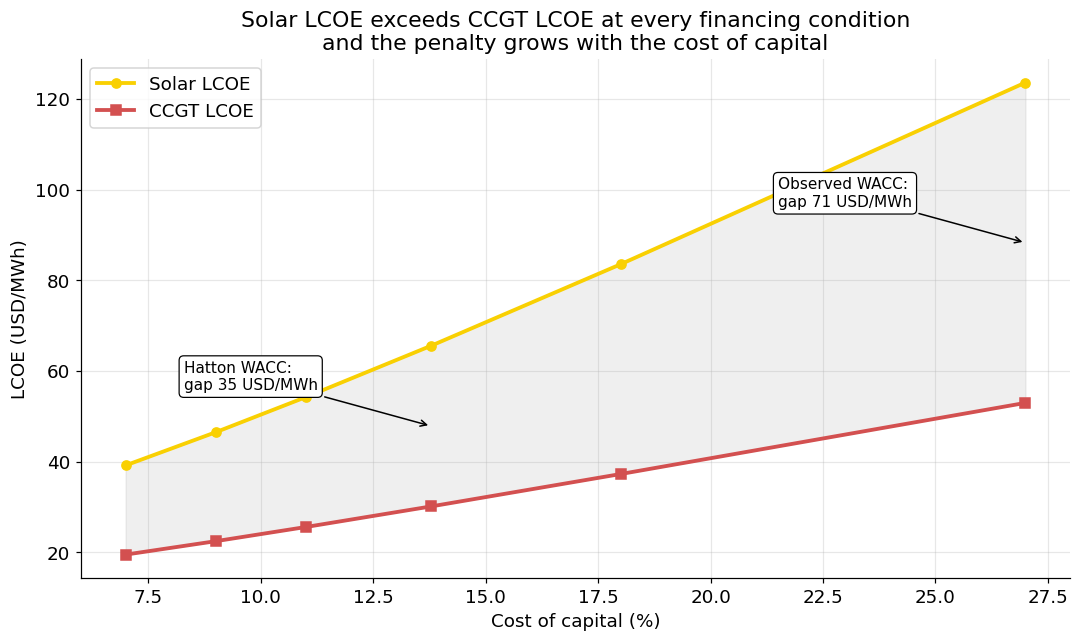

In [24]:
fig, ax = plt.subplots(figsize=(10,6))
x = lcoe_tbl.wacc_pct

ax.plot(x, lcoe_tbl.solar_lcoe, "o-", color="#f9d002", lw=2.5, label="Solar LCOE")
ax.plot(x, lcoe_tbl.ccgt_lcoe, "s-", color="#d35050", lw=2.5, label="CCGT LCOE")
ax.fill_between(x, lcoe_tbl.ccgt_lcoe, lcoe_tbl.solar_lcoe, alpha=0.12, color="grey")

# Annotate the two gaps you care about, at the two WACCs the paper uses
for w, note in [(13.79, "Hatton WACC:\ngap 35 USD/MWh"),
                (27.0, "Observed WACC:\ngap 71 USD/MWh")]:
    row = lcoe_tbl[lcoe_tbl.wacc_pct.round(2)==w].iloc[0]
    mid = (row.solar_lcoe + row.ccgt_lcoe)/2
    ax.annotate(note,
                xy=(w, mid),
                xytext=(w - 5.5, mid + 8),
                fontsize=10,
                arrowprops=dict(arrowstyle="->", color="black", lw=1),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=0.8))

ax.set_xlabel("Cost of capital (%)")
ax.set_ylabel("LCOE (USD/MWh)")
ax.set_title("Solar LCOE exceeds CCGT LCOE at every financing condition\n"
             "and the penalty grows with the cost of capital")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(OUT/"rq3_lcoe_annotated.png", bbox_inches="tight"); plt.show()

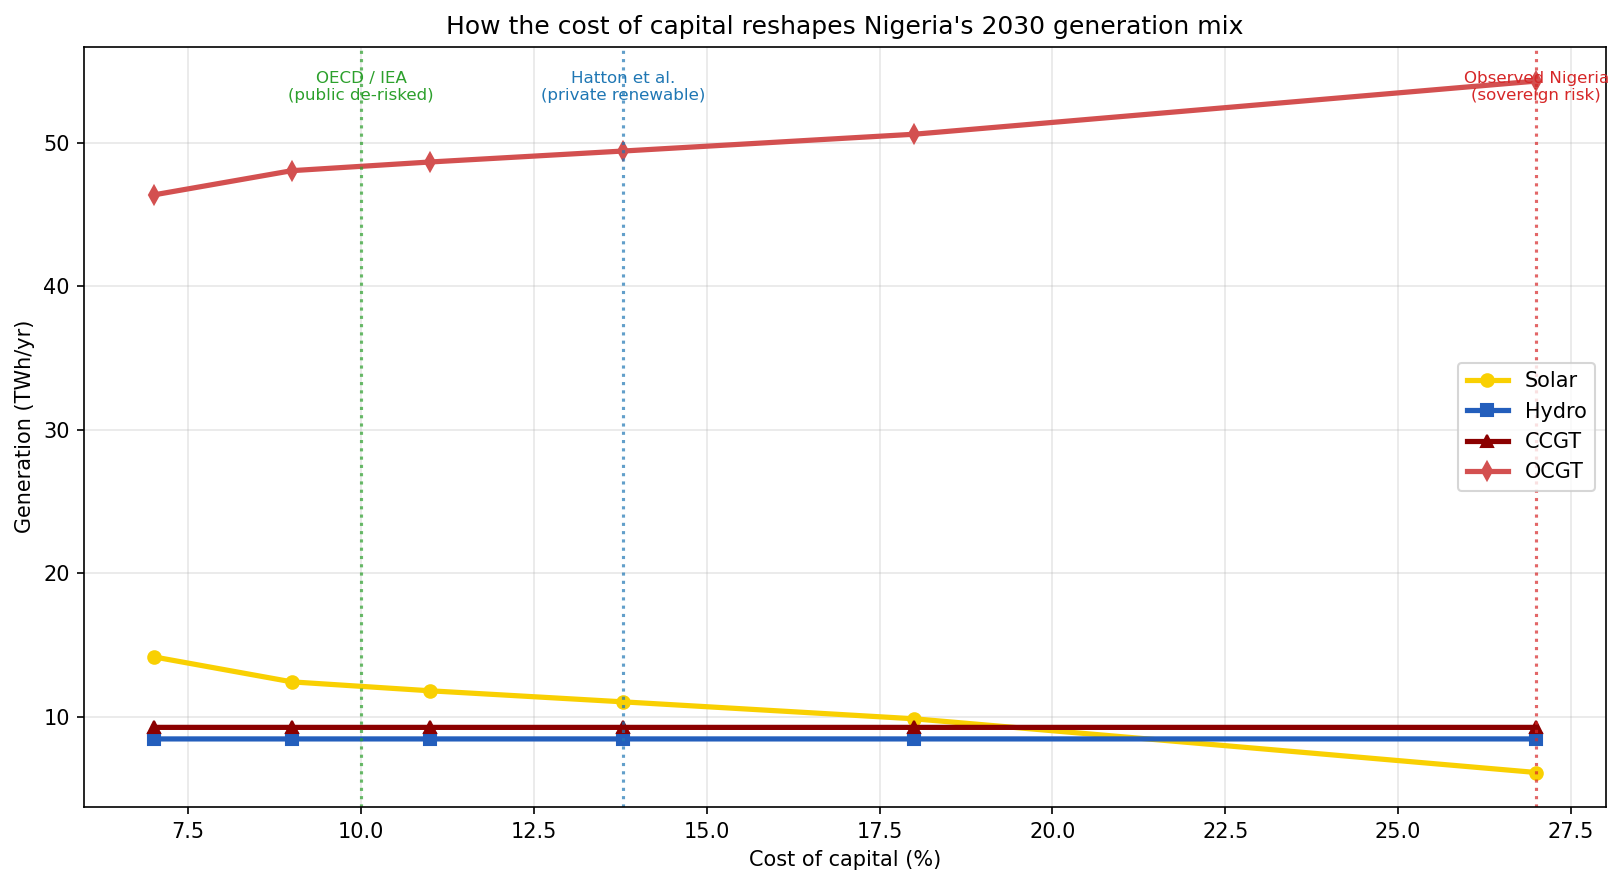

In [ ]:
fig, ax = plt.subplots(figsize=(11,6))
x = unc.wacc*100

ax.plot(x, unc.gen_solar_twh, "o-", color="#f9d002", lw=2.5, label="Solar")
ax.plot(x, unc.gen_hydro_twh, "s-", color="#235ebc", lw=2.5, label="Hydro")
ax.plot(x, unc.gen_CCGT_twh, "^-", color="#8b0000", lw=2.5, label="CCGT")
ax.plot(x, unc.gen_OCGT_twh, "d-", color="#d35050", lw=2.5, label="OCGT")

# Empirical reference lines with meaning, not just numbers
refs = [
    (10.0, "OECD / IEA\n(public de-risked)",       "#2ca02c"),
    (13.79,"Hatton et al.\n(private renewable)",   "#1f77b4"),
    (27.0, "Observed Nigeria\n(sovereign risk)",   "#d62728"),
]
for val, label, col in refs:
    ax.axvline(val, color=col, ls=":", alpha=0.7, lw=1.5)
    ax.text(val, ax.get_ylim()[1]*0.97, label, fontsize=8, color=col,
            ha="center", va="top", rotation=0)

ax.set_xlabel("Cost of capital (%)")
ax.set_ylabel("Generation (TWh/yr)")
ax.set_title("How the cost of capital reshapes Nigeria's 2030 generation mix")
ax.legend(loc="center right")
plt.tight_layout(); plt.savefig(OUT/"rq1_mix_labelled.png", bbox_inches="tight"); plt.show()

In [ ]:
ax.axvline(10, color="purple", ls=":", alpha=0.7)
ax.text(10.1, ax.get_ylim()[1]*0.9, "OECD 10%", fontsize=8, color="purple")

Text(10.1, 51.047664335507505, 'OECD 10%')

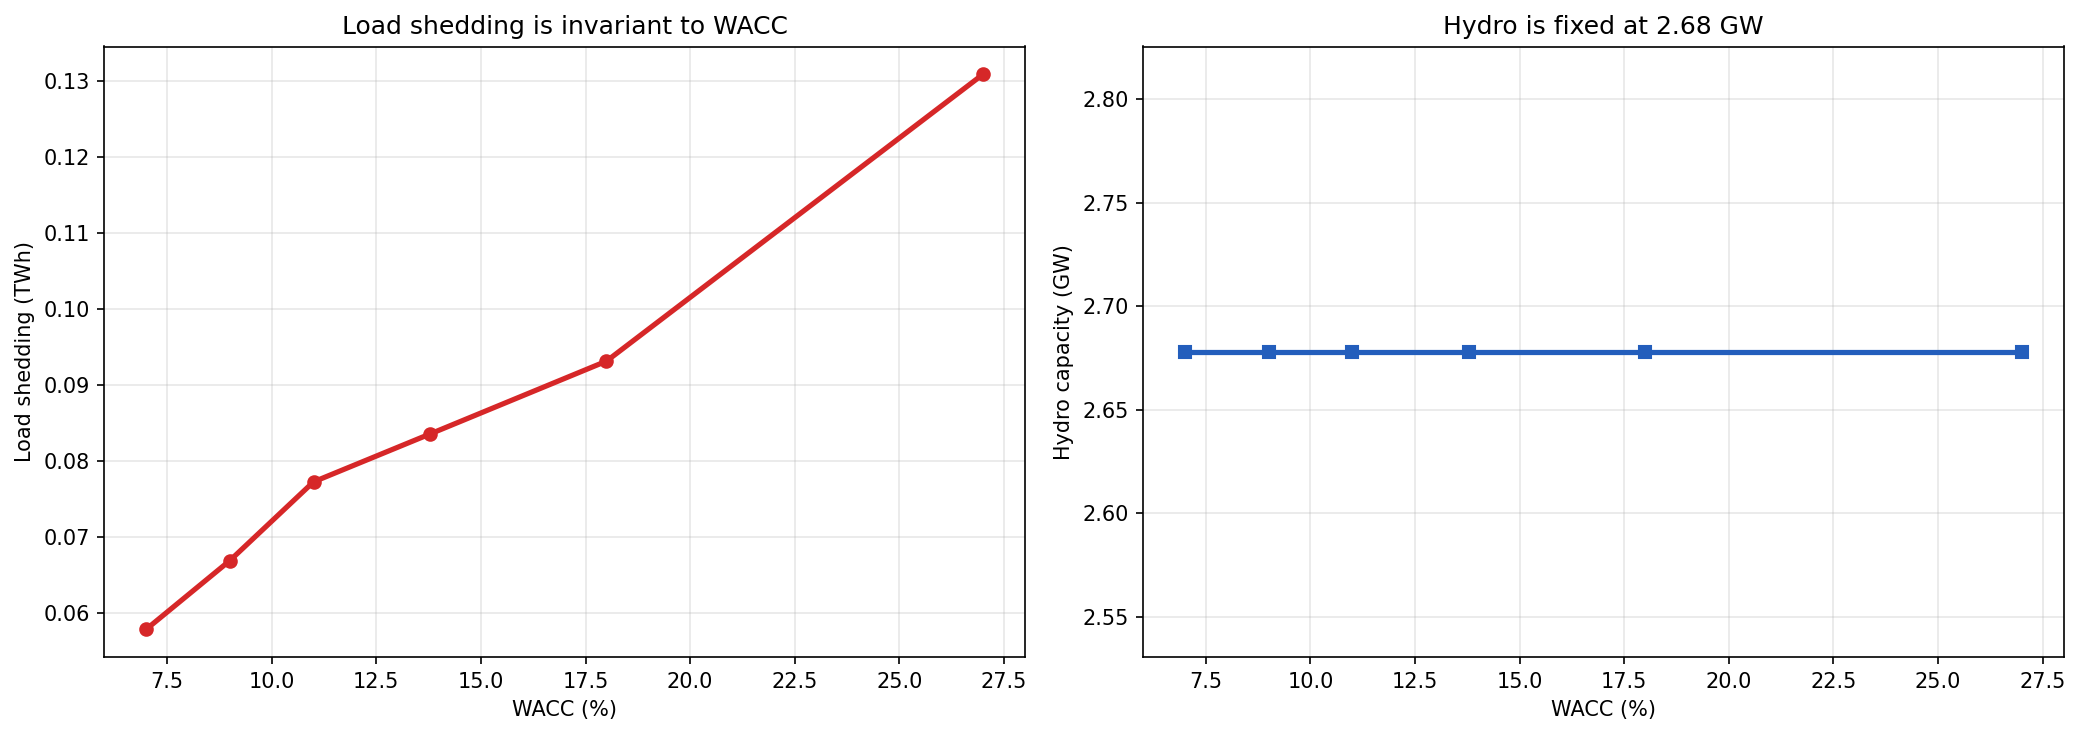

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
x = unc.wacc*100

axes[0].plot(x, unc.shed_twh, "o-", color="#d62728", lw=2.5)
axes[0].set_xlabel("WACC (%)"); axes[0].set_ylabel("Load shedding (TWh)")
axes[0].set_title("Load shedding is invariant to WACC")

axes[1].plot(x, unc.cap_hydro_gw, "s-", color="#235ebc", lw=2.5)
axes[1].set_xlabel("WACC (%)"); axes[1].set_ylabel("Hydro capacity (GW)")
axes[1].set_title("Hydro is fixed at 2.68 GW")
plt.tight_layout(); plt.savefig(OUT/"rq1_hydro_shed.png", bbox_inches="tight"); plt.show()

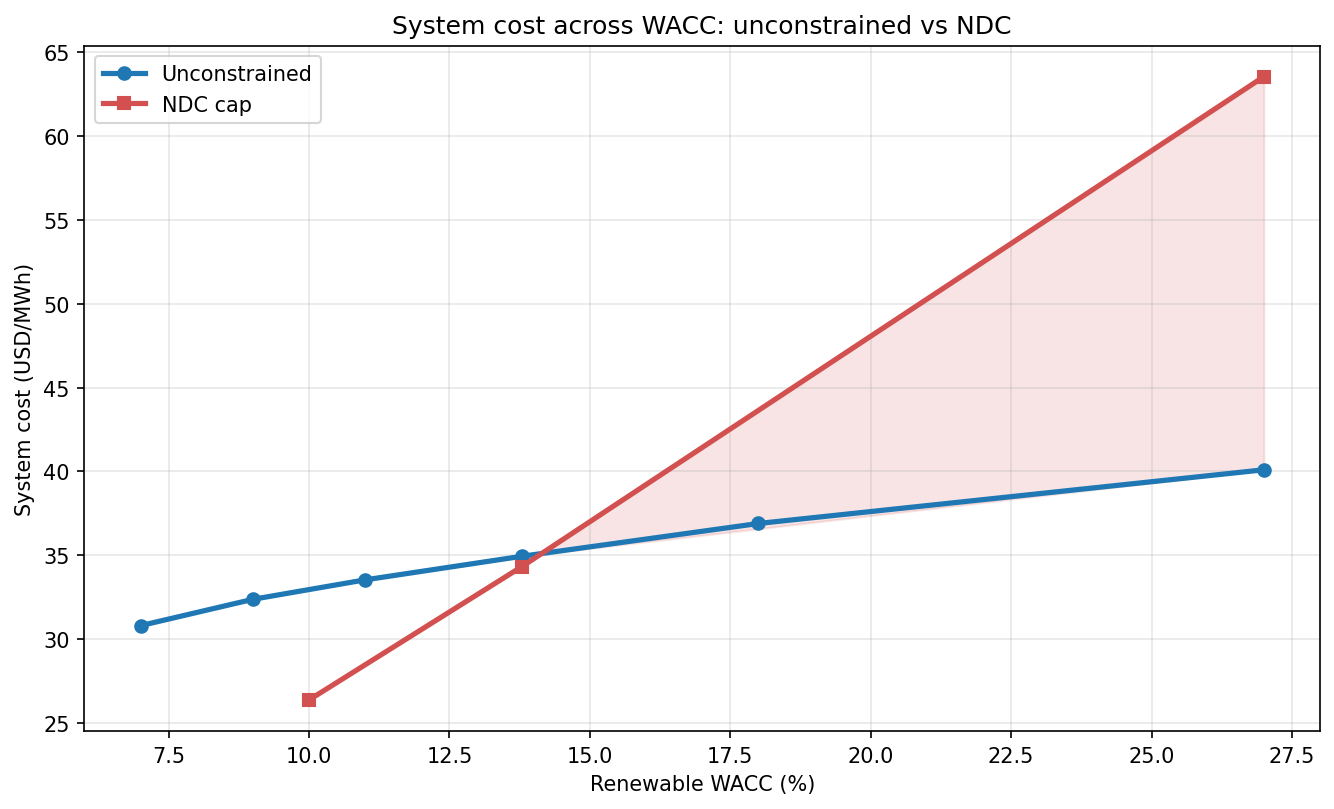

In [ ]:
fig, ax = plt.subplots(figsize=(9,5.5))
ax.plot(unc.wacc*100, unc.cost_per_mwh_usd, "o-", color="#1f77b4", lw=2.5, label="Unconstrained")
ax.plot(ndc.wacc*100, ndc.cost_per_mwh_usd, "s-", color="#d35050", lw=2.5, label="NDC cap")
ax.fill_between(ndc.wacc*100, 
                unc.set_index(unc.wacc.round(4)).reindex(ndc.wacc.round(4))["cost_per_mwh_usd"].values,
                ndc.cost_per_mwh_usd.values,
                alpha=0.15, color="#d35050")
ax.set_xlabel("Renewable WACC (%)")
ax.set_ylabel("System cost (USD/MWh)")
ax.set_title("System cost across WACC: unconstrained vs NDC")
ax.legend()
plt.tight_layout(); plt.savefig(OUT/"rq4_cost_vs_wacc.png", bbox_inches="tight"); plt.show()

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


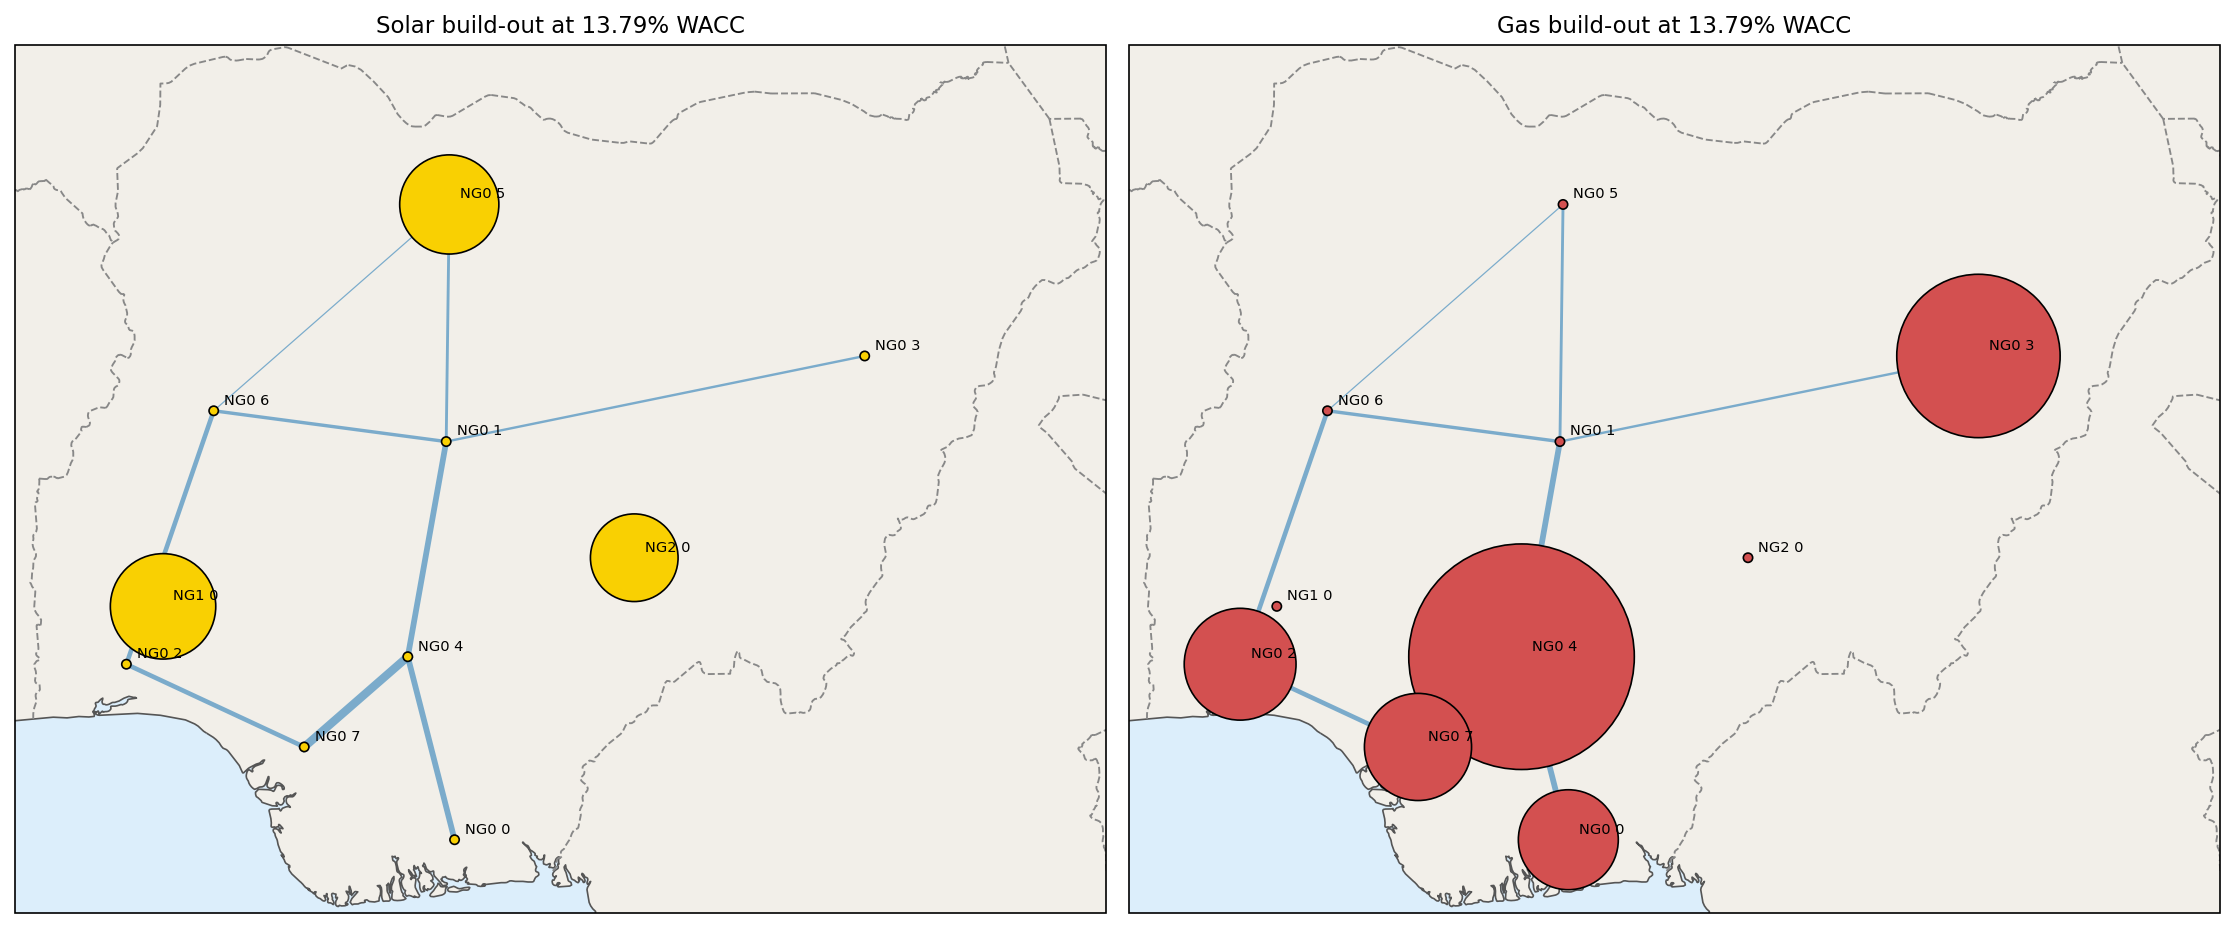

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

n2030 = load_network("nigeria_2030_wacc_1379")

fig, axes = plt.subplots(1, 2, figsize=(15, 9), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (which, title) in zip(axes, [
    ("solar",  "Solar build-out at 13.79% WACC"),
    ("gas",    "Gas build-out at 13.79% WACC"),
]):
    ax.set_extent([2.5, 14.7, 4.2, 13.9], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="#f2efe9", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="#dceefb", zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor="#555")
    ax.add_feature(cfeature.BORDERS, linewidth=0.9, ls="--", edgecolor="#888")

    # Lines coloured by utilisation if dispatch data present
    for _, ln in n2030.lines.iterrows():
        b0 = n2030.buses.loc[ln.bus0]; b1 = n2030.buses.loc[ln.bus1]
        lw = 0.5 + 3.5*(ln.s_nom_opt/n2030.lines.s_nom_opt.max()) if n2030.lines.s_nom_opt.max()>0 else 1
        ax.plot([b0.x,b1.x],[b0.y,b1.y], color="#2c7fb8", lw=lw, alpha=0.6,
                transform=ccrs.PlateCarree(), zorder=2)

    # Capacity at each bus, coloured by carrier
    if which == "solar":
        sel = n2030.generators[n2030.generators.carrier=="solar"]
        col, lab = "#f9d002", "Solar GW"
    else:
        sel = n2030.generators[n2030.generators.carrier.isin(["CCGT","OCGT"])]
        col, lab = "#d35050", "Gas GW"

    cap = sel.groupby("bus").p_nom_opt.sum()
    cap = cap.reindex(n2030.buses.index).fillna(0)
    sc = ax.scatter(n2030.buses.x, n2030.buses.y,
                    s=20 + 0.8*cap,
                    c=col, edgecolor="black", linewidth=0.8,
                    zorder=3, transform=ccrs.PlateCarree())
    for name, row in n2030.buses.iterrows():
        ax.annotate(name, (row.x, row.y), textcoords="offset points",
                    xytext=(5,3), fontsize=7, transform=ccrs.PlateCarree())
    ax.set_title(title, fontsize=11)

plt.tight_layout(); plt.savefig(OUT/"rq_map_2030.png", bbox_inches="tight"); plt.show()

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


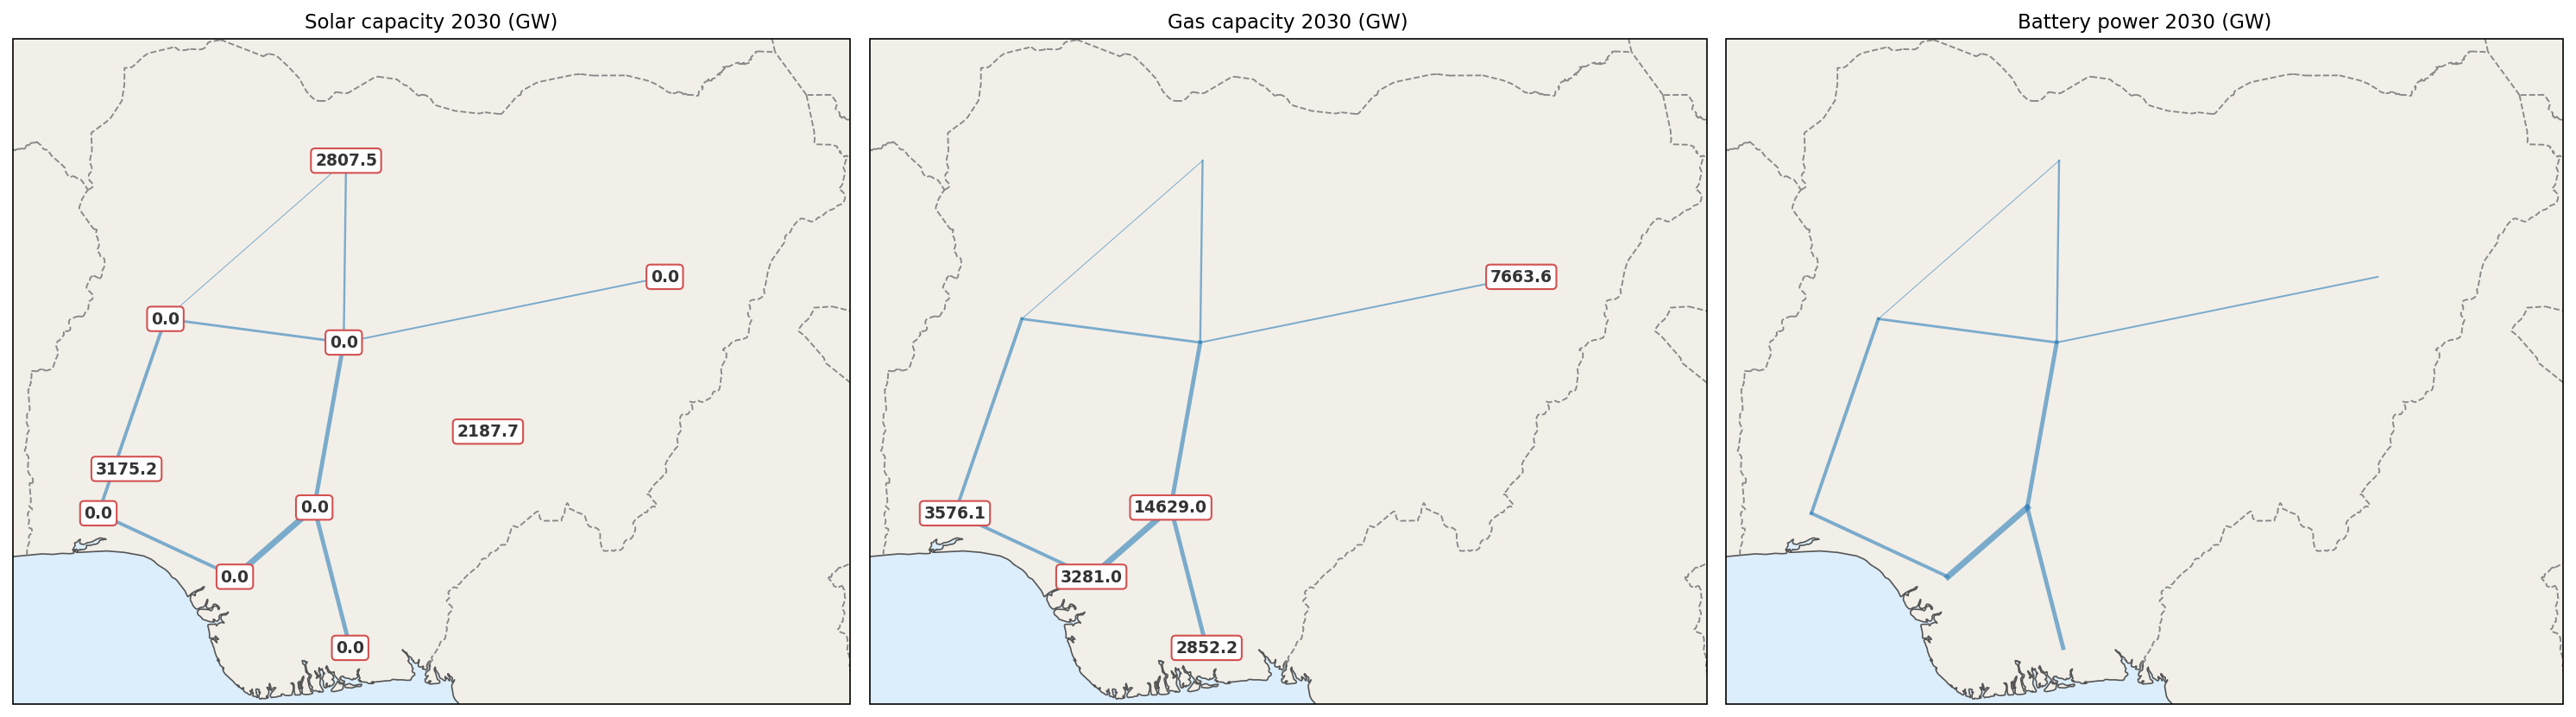

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

n2030 = load_network("nigeria_2030_wacc_1379")

def draw_map(ax, carrier_list, title, fmt):
    ax.set_extent([2.5, 14.7, 4.2, 13.9], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="#f2efe9", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="#dceefb", zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor="#555")
    ax.add_feature(cfeature.BORDERS, linewidth=0.9, ls="--", edgecolor="#888")

    # transmission lines, thickness by thermal rating
    for _, ln in n2030.lines.iterrows():
        b0 = n2030.buses.loc[ln.bus0]; b1 = n2030.buses.loc[ln.bus1]
        lw = 0.4 + 3.0*(ln.s_nom_opt/n2030.lines.s_nom_opt.max()) if n2030.lines.s_nom_opt.max()>0 else 1
        ax.plot([b0.x,b1.x],[b0.y,b1.y], color="#2c7fb8", lw=lw, alpha=0.6,
                transform=ccrs.PlateCarree(), zorder=2)

    # numeric capacity at each bus
    cap = (n2030.generators[n2030.generators.carrier.isin(carrier_list)]
           .groupby("bus").p_nom_opt.sum())
    cap = cap.reindex(n2030.buses.index).fillna(0)
    for bus, val in cap.items():
        if val <= 0: continue
        row = n2030.buses.loc[bus]
        ax.annotate(f"{fmt.format(val)}", (row.x, row.y),
                    fontsize=9, fontweight="bold", color="#333",
                    ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#d35050", lw=1),
                    transform=ccrs.PlateCarree(), zorder=4)
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(20, 9), subplot_kw={"projection": ccrs.PlateCarree()})
draw_map(axes[0], ["solar"],                       "Solar capacity 2030 (GW)",      "{:.1f}")
draw_map(axes[1], ["CCGT","OCGT"],                 "Gas capacity 2030 (GW)",        "{:.1f}")
draw_map(axes[2], ["battery"],                     "Battery power 2030 (GW)",       "{:.1f}")
plt.tight_layout(); plt.savefig(OUT/"rq_map_2030_numeric.png", bbox_inches="tight"); plt.show()

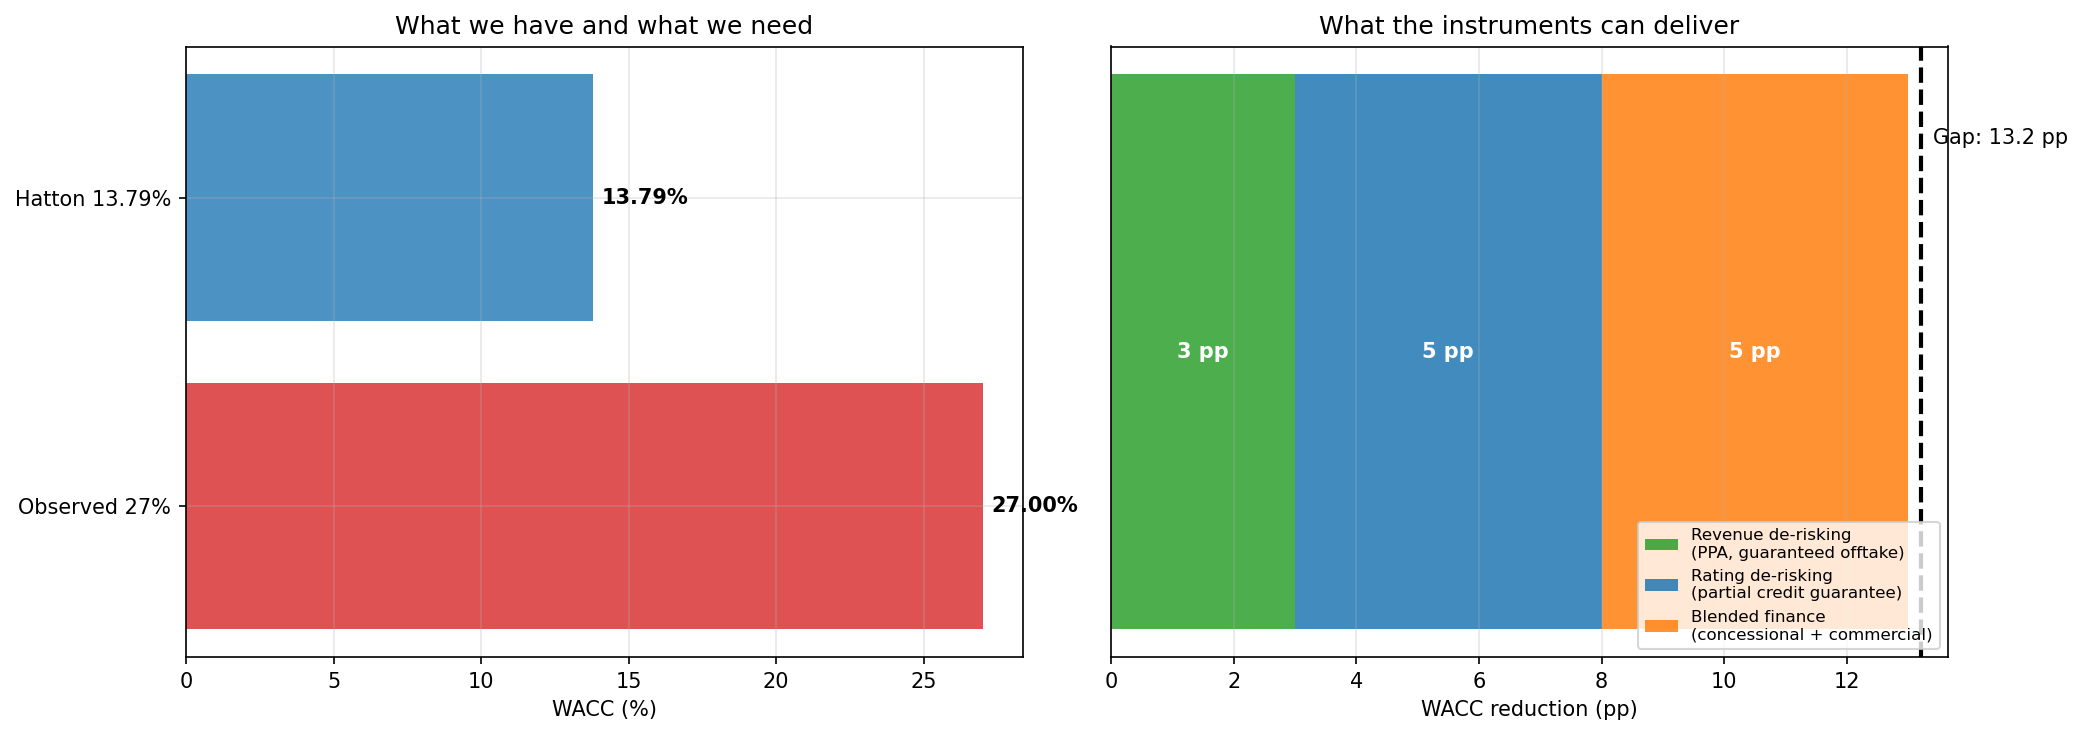

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Left: what is needed
axes[0].barh(["Observed 27%", "Hatton 13.79%"], [27, 13.79],
             color=["#d62728","#1f77b4"], alpha=0.8)
axes[0].set_xlabel("WACC (%)")
axes[0].set_title("What we have and what we need")
for i, v in enumerate([27, 13.79]):
    axes[0].text(v+0.3, i, f"{v:.2f}%", va="center", fontweight="bold")

# Right: what each instrument can deliver
instr = pd.DataFrame({
    "Instrument": ["Revenue de-risking\n(PPA, guaranteed offtake)",
                   "Rating de-risking\n(partial credit guarantee)",
                   "Blended finance\n(concessional + commercial)"],
    "Effect_pp": [3, 5, 5],
})
cum = 0
for i, row in instr.iterrows():
    axes[1].barh([0], [row.Effect_pp], left=cum, color=["#2ca02c","#1f77b4","#ff7f0e"][i],
                 alpha=0.85, label=row.Instrument)
    axes[1].text(cum + row.Effect_pp/2, 0, f"{row.Effect_pp} pp",
                 ha="center", va="center", color="white", fontweight="bold")
    cum += row.Effect_pp
axes[1].axvline(13.21, color="black", ls="--", lw=2)
axes[1].text(13.21+0.2, 0.3, "Gap: 13.2 pp", fontsize=10)
axes[1].set_xlabel("WACC reduction (pp)")
axes[1].set_title("What the instruments can deliver")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].set_yticks([])

plt.tight_layout(); plt.savefig(OUT/"rq5_policy_two_panel.png", bbox_inches="tight"); plt.show()

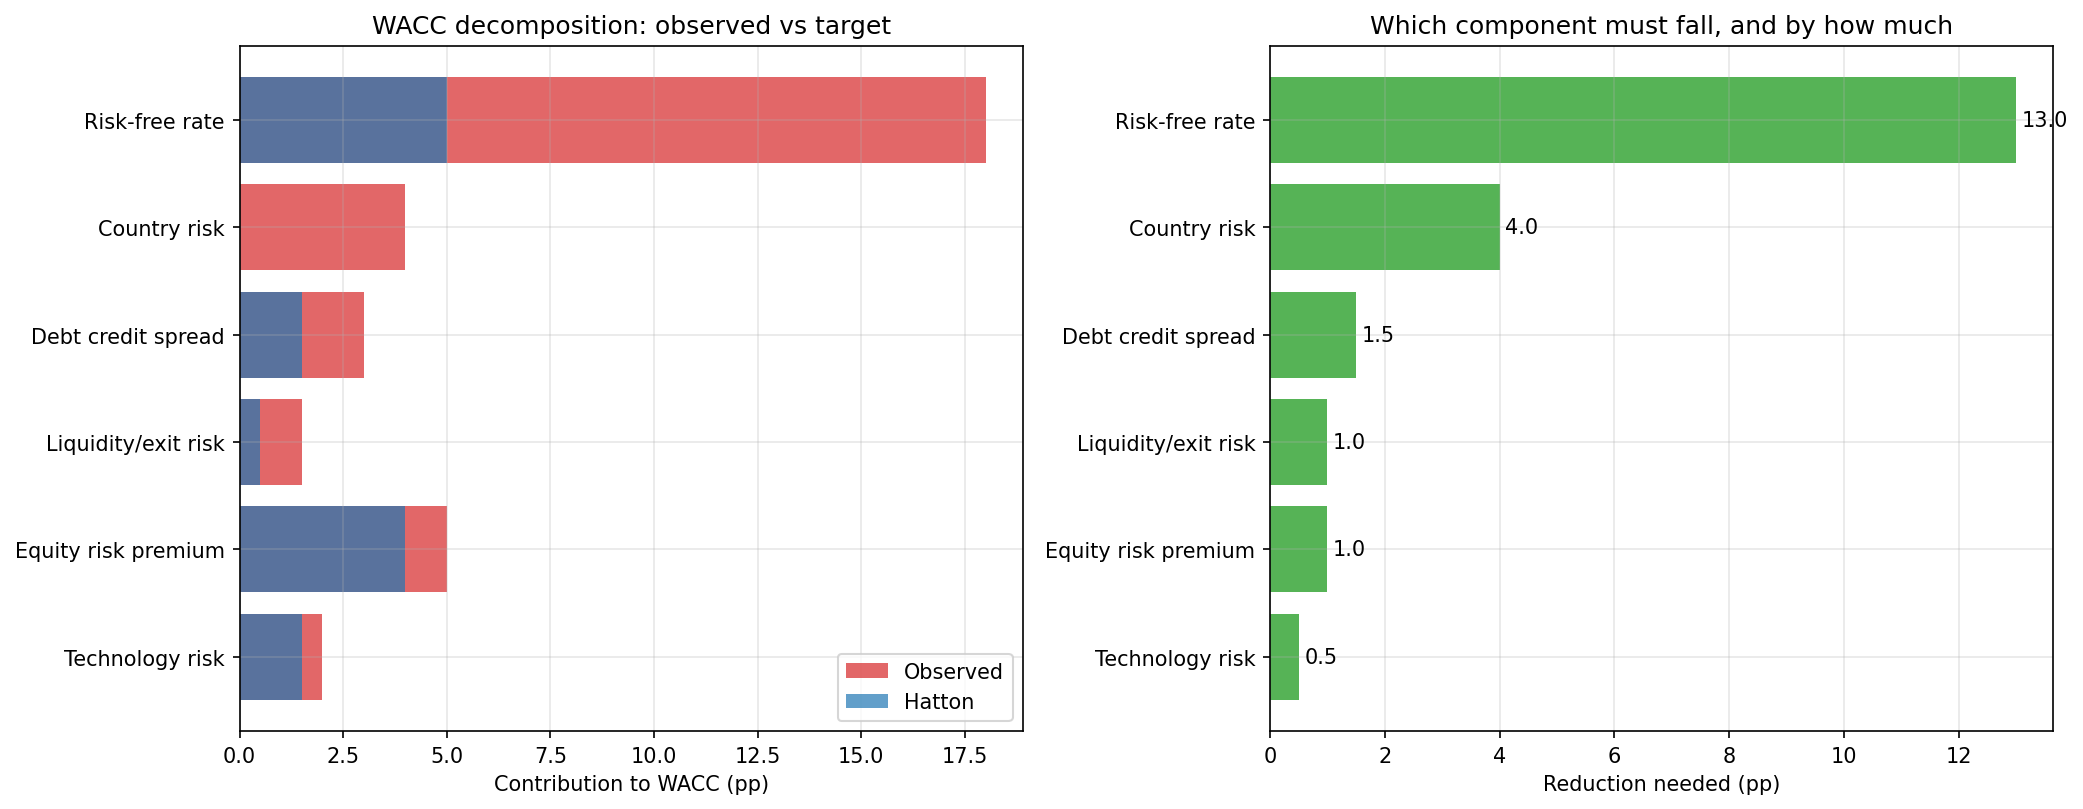

In [ ]:
components = pd.DataFrame({
    "Component": ["Risk-free rate","Equity risk premium","Country risk",
                  "Technology risk","Liquidity/exit risk","Debt credit spread"],
    "Observed_pp":  [18.0, 5.0, 4.0, 2.0, 1.5, 3.0],
    "Hatton_pp":    [ 5.0, 4.0, 0.0, 1.5, 0.5, 1.5],
})
components["Reduction_pp"] = components.Observed_pp - components.Hatton_pp
components = components.sort_values("Reduction_pp", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14,5.5))

# left: composition
axes[0].barh(components.Component, components.Observed_pp, color="#d62728", alpha=0.7, label="Observed")
axes[0].barh(components.Component, components.Hatton_pp, color="#1f77b4", alpha=0.7, label="Hatton")
axes[0].set_xlabel("Contribution to WACC (pp)")
axes[0].set_title("WACC decomposition: observed vs target")
axes[0].legend()

# right: reduction by component
axes[1].barh(components.Component, components.Reduction_pp, color="#2ca02c", alpha=0.8)
axes[1].set_xlabel("Reduction needed (pp)")
axes[1].set_title("Which component must fall, and by how much")
for i, v in enumerate(components.Reduction_pp):
    axes[1].text(v+0.1, i, f"{v:.1f}", va="center")

plt.tight_layout(); plt.savefig(OUT/"rq5_wacc_decomposition.png", bbox_inches="tight"); plt.show()

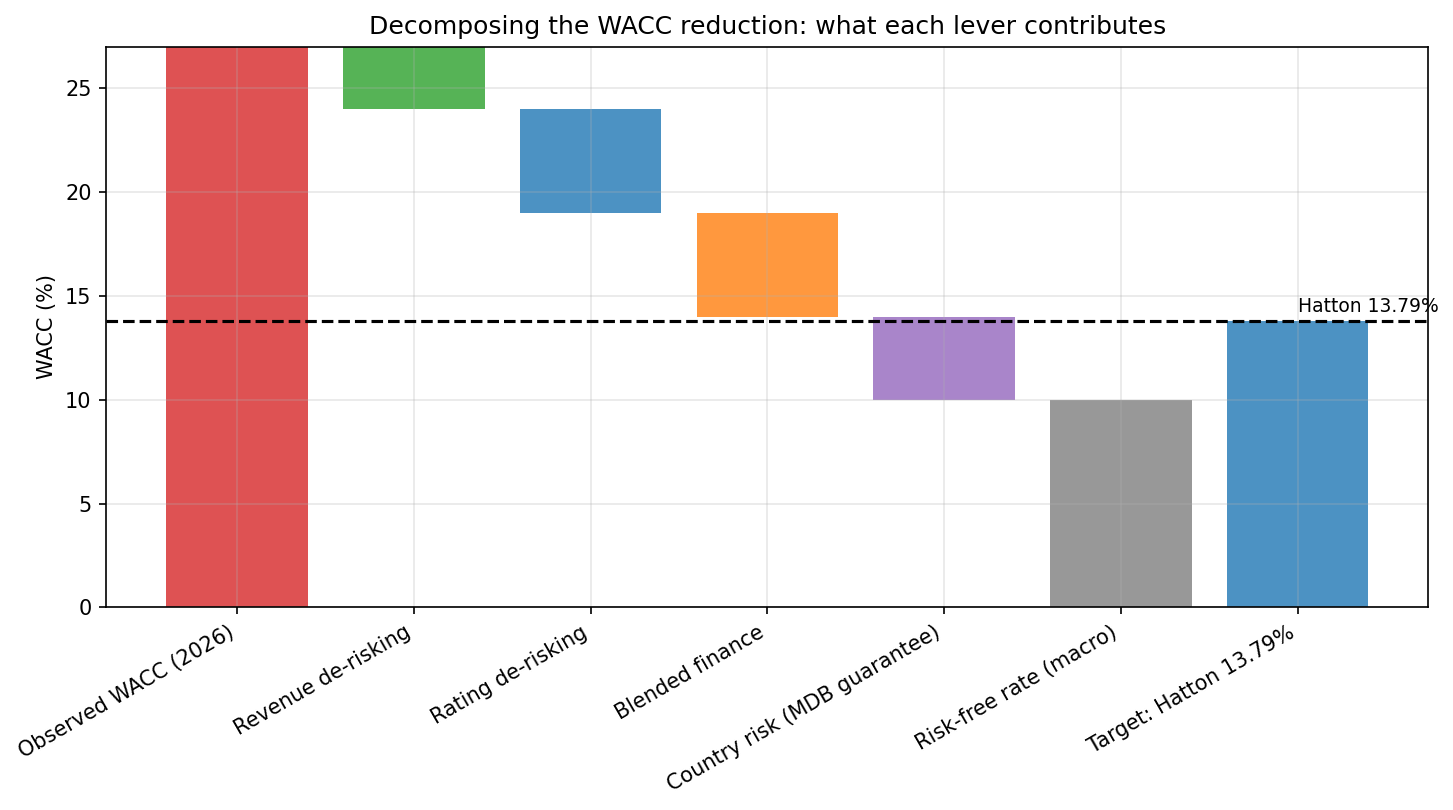

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
items = [
    ("Observed WACC (2026)",          27.0, "#d62728"),
    ("Revenue de-risking",            -3.0, "#2ca02c"),
    ("Rating de-risking",             -5.0, "#1f77b4"),
    ("Blended finance",               -5.0, "#ff7f0e"),
    ("Country risk (MDB guarantee)",  -4.0, "#9467bd"),
    ("Risk-free rate (macro)",        -10.0, "#7f7f7f"),
    ("Target: Hatton 13.79%",         13.79, "#1f77b4"),
]
y = 0
for label, delta, col in items:
    if delta > 0:
        ax.bar(label, delta, color=col, alpha=0.8)
    else:
        ax.bar(label, delta, bottom=27.0 + sum(x[1] for x in items[:y] if x[1] < 0),
               color=col, alpha=0.8)
    y += 1
ax.axhline(13.79, color="black", ls="--", lw=1.5)
ax.text(len(items)-1, 14.2, "Hatton 13.79%", fontsize=9)
ax.set_ylabel("WACC (%)")
ax.set_title("Decomposing the WACC reduction: what each lever contributes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(OUT/"rq5_wacc_stack.png", bbox_inches="tight"); plt.show()

NDC vs unconstrained at matched WACC:
 wacc_pct  ndc_cost  unc_cost  ndc_emit  premium
    10.00     56.38     44.20      8.82    12.18
    13.79     71.09     47.49      8.82    23.60
    27.00    122.57     57.46      8.82    65.11


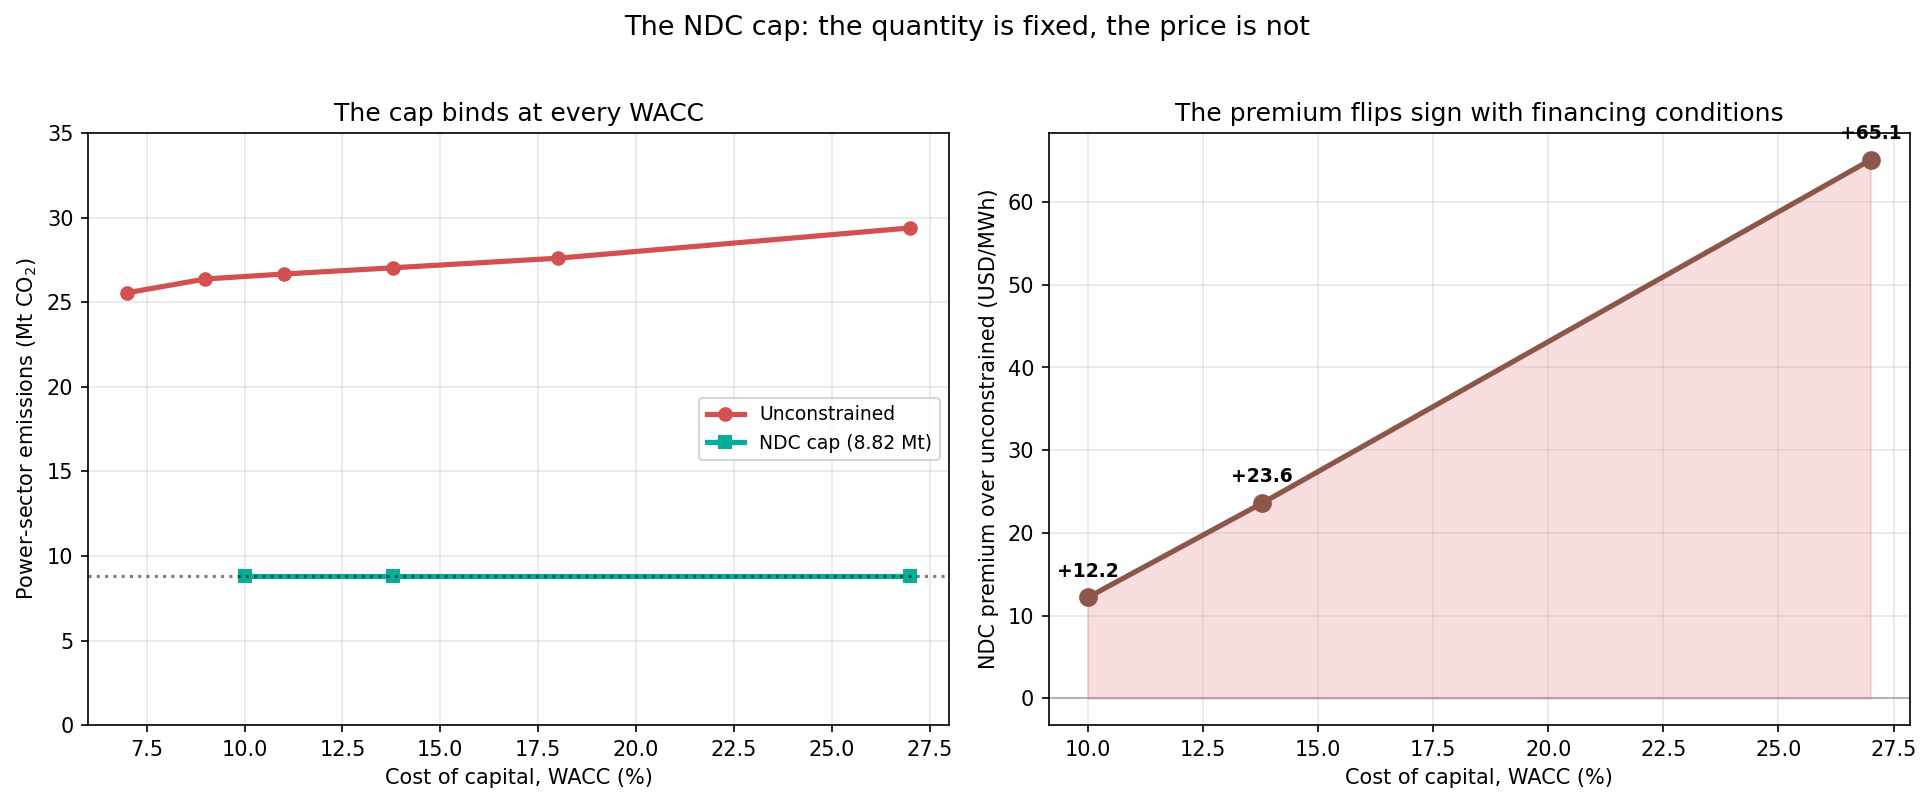

In [10]:
# ==== NDC slide: two-panel figure ====
import matplotlib.pyplot as plt
import numpy as np

# --- rebuild unc and ndc from sweep if not in memory ---
if "unc" not in dir():
    unc = sweep[sweep.constraint=="unconstrained"].sort_values("wacc").reset_index(drop=True)
if "ndc" not in dir():
    ndc = sweep[sweep.constraint=="ndc"].sort_values("wacc").reset_index(drop=True)

# --- interpolate unconstrained cost to the NDC WACC points ---
def interp_cost(wacc_target):
    """Linear interpolation of unconstrained cost_per_mwh_usd at a given WACC."""
    x = unc.wacc.values
    y = unc.cost_per_mwh_usd.values
    return float(np.interp(wacc_target, x, y))

premium = pd.DataFrame({
    "wacc_pct":   (ndc.wacc * 100).round(2),
    "ndc_cost":   ndc.cost_per_mwh_usd.round(2),
    "unc_cost":   [round(interp_cost(w), 2) for w in ndc.wacc],
    "ndc_emit":   ndc.emissions_mt_co2.round(2),
})
premium["premium"] = (premium.ndc_cost - premium.unc_cost).round(2)

print("NDC vs unconstrained at matched WACC:")
print(premium.to_string(index=False))

# --- figure ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# LEFT: emissions — cap binds, unconstrained rises
ax = axes[0]
ax.plot(unc.wacc*100, unc.emissions_mt_co2, "o-",
        color="#d35050", lw=2.5, label="Unconstrained")
ax.plot(ndc.wacc*100, ndc.emissions_mt_co2, "s-",
        color="#08ad97", lw=2.5, label="NDC cap (8.82 Mt)")
ax.axhline(8.82, ls=":", color="black", alpha=0.5)
ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("Power-sector emissions (Mt CO$_2$)")
ax.set_title("The cap binds at every WACC")
ax.legend(loc="center right", fontsize=9)
ax.set_ylim(0, 35)

# RIGHT: premium of NDC over unconstrained
ax = axes[1]
ax.plot(premium.wacc_pct, premium.premium, "o-",
        color="#8c564b", lw=2.5, ms=8)
ax.axhline(0, ls="-", color="grey", alpha=0.5, lw=1)
for _, r in premium.iterrows():
    ax.annotate(f"{r.premium:+.1f}",
                (r.wacc_pct, r.premium),
                textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold")
ax.fill_between(premium.wacc_pct, premium.premium, 0,
                where=(premium.premium > 0), color="#d62728", alpha=0.15)
ax.fill_between(premium.wacc_pct, premium.premium, 0,
                where=(premium.premium < 0), color="#2ca02c", alpha=0.15)
ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("NDC premium over unconstrained (USD/MWh)")
ax.set_title("The premium flips sign with financing conditions")

fig.suptitle("The NDC cap: the quantity is fixed, the price is not",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUT / "fig_ndc_two_panel.png", bbox_inches="tight", dpi=300)
plt.show()

Runs found:
                           run  wacc  gas     kind
        nigeria_2030_wacc_0700  7.00 3.39 baseline
        nigeria_2030_wacc_0900  9.00 3.39 baseline
        nigeria_2030_wacc_1100 11.00 3.39 baseline
        nigeria_2030_wacc_1379 13.79 3.39 baseline
        nigeria_2030_wacc_1800 18.00 3.39 baseline
        nigeria_2030_wacc_2000 20.00 3.39 baseline
        nigeria_2030_wacc_2700 27.00 3.39 baseline
nigeria_2030_wacc_0700_gas_600  7.00 6.00      gas
nigeria_2030_wacc_1379_gas_600 13.79 6.00      gas
nigeria_2030_wacc_2000_gas_600 20.00 6.00      gas


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_0700
loaded nigeria_2030_wacc_0900


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1100
loaded nigeria_2030_wacc_1379


...

loaded nigeria_2030_wacc_1800
loaded nigeria_2030_wacc_2000


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_2700
loaded nigeria_2030_wacc_0700_gas_600


INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


loaded nigeria_2030_wacc_1379_gas_600
loaded nigeria_2030_wacc_2000_gas_600

                           run  wacc  gas  cap_solar  share_renew  cost_usd_mwh
        nigeria_2030_wacc_0700  7.00 3.39     10.351       28.912        40.781
        nigeria_2030_wacc_0900  9.00 3.39      9.198       26.700        42.445
        nigeria_2030_wacc_1100 11.00 3.39      8.688       25.910        44.015
        nigeria_2030_wacc_1379 13.79 3.39      8.170       24.927        46.332
        nigeria_2030_wacc_1800 18.00 3.39      7.377       23.419        49.711
        nigeria_2030_wacc_2000 20.00 3.39      7.377       23.419        49.711
        nigeria_2030_wacc_2700 27.00 3.39      4.897       18.637        55.519
nigeria_2030_wacc_0700_gas_600  7.00 6.00     10.482       29.200        42.048
nigeria_2030_wacc_1379_gas_600 13.79 6.00      8.338       25.299        47.673
nigeria_2030_wacc_2000_gas_600 20.00 6.00      7.508       23.712        51.080

Gas surface (paired deltas vs $3.39 baseli

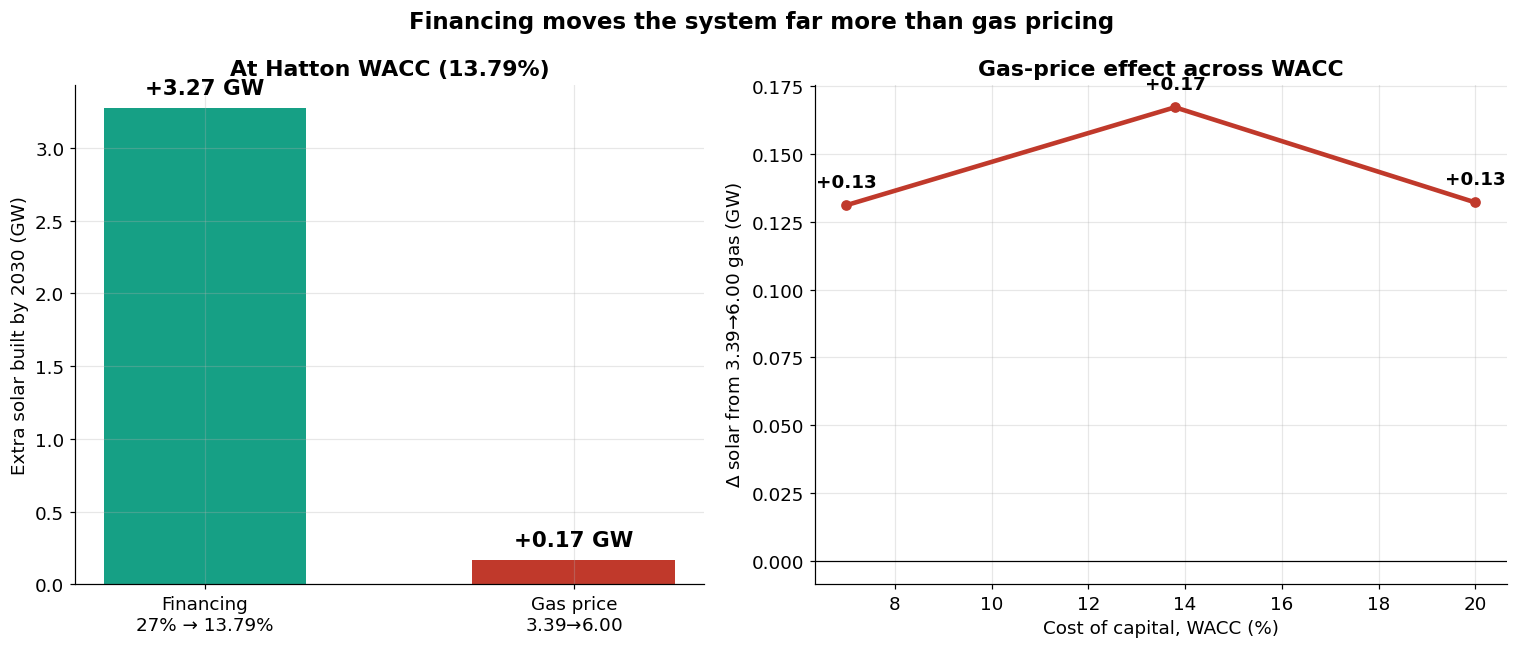


Suggested Slide 6 caption:
  Gas-price effect ranges from +0.13 GW at 7.00% WACC to +0.13 GW at 20.00% WACC, vs +3.27 GW from financing (WACC 27% → 13.79%).


In [11]:
# ============================================================
# Gas surface — run this after the three new runs complete
# ============================================================
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pypsa

RESULTS = Path("/Users/fowfloi/Documents/pypsa-earth/results")
OUT     = Path("/Users/fowfloi/Documents/pypsa-earth/analysis")
OUT.mkdir(exist_ok=True)
USD_PER_EUR = 1.3277
BASE_GAS_PRICE = 3.39
COL = {"solar":"#E3A800","gas":"#C0392B","battery":"#16A085"}
SHED = {"load shedding","load"}
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":300,"font.size":12,
                     "axes.grid":True,"grid.alpha":0.3,
                     "axes.spines.top":False,"axes.spines.right":False})

# ------------------------------------------------------------
# 1. Which runs exist?
# ------------------------------------------------------------
WACC_SWEEP = ["0700","0900","1100","1200","1300","1379","1468",
              "1600","1800","2000","2300","2700"]
GAS600_TAGS = ["0700","1379","2000"]

def find_network(name):
    p = RESULTS / name / "networks"
    if not p.exists(): return None
    hits = list(p.glob("elec_s_*_lcopt_*.nc"))
    return hits[0] if hits else None

def parse(name):
    m = re.match(r"^nigeria_2030_wacc_(\d{4})(?:_gas_(\d+))?$", name)
    if not m: return None
    wacc = int(m.group(1))/100
    gas  = int(m.group(2))/100 if m.group(2) else BASE_GAS_PRICE
    return dict(run=name, wacc=wacc, gas=gas,
                kind="gas" if m.group(2) else "baseline")

RUNS = [f"nigeria_2030_wacc_{t}" for t in WACC_SWEEP] + \
       [f"nigeria_2030_wacc_{t}_gas_600" for t in GAS600_TAGS]

present = []
for r in RUNS:
    meta = parse(r)
    if meta is None: continue
    if find_network(r) is not None:
        present.append(meta)
df = pd.DataFrame(present).sort_values(["kind","wacc"]).reset_index(drop=True)
print("Runs found:")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. Summarise (same function as the main notebook)
# ------------------------------------------------------------
def load(name):
    return pypsa.Network(str(find_network(name)))

def weighted(x, n): return x.mul(n.snapshot_weightings.generators, axis=0)

def summarise(n):
    g, s = n.generators, n.storage_units
    real = g[~g.carrier.isin(SHED)]
    P  = weighted(n.generators_t.p.reindex(columns=g.index, fill_value=0), n)
    SP = weighted(n.storage_units_t.p.reindex(columns=s.index, fill_value=0), n) if len(s) else pd.DataFrame()
    r = {}
    cap = real.groupby("carrier").p_nom_opt.sum()/1e3
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"cap_{c}"] = float(cap.get(c,0))
    r["cap_gas"] = r["cap_CCGT"] + r["cap_OCGT"]
    r["cap_battery"] = float(s[s.carrier=="battery"].p_nom_opt.sum()/1e3) if len(s) else 0.0

    gen = P[real.index].sum().groupby(real.carrier).sum()/1e6
    hydro_sto = SP[s[s.carrier=="hydro"].index].clip(lower=0).sum().sum()/1e6 if len(s) else 0.0
    for c in ["solar","onwind","CCGT","OCGT"]:
        r[f"gen_{c}"] = float(gen.get(c,0))
    r["gen_hydro"] = float(hydro_sto + gen.get("ror",0) + gen.get("hydro",0))
    r["gen_gas"]   = r["gen_CCGT"] + r["gen_OCGT"]
    total = r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"]+r["gen_gas"] \
            + float(gen.drop(["solar","onwind","CCGT","OCGT","ror","hydro"], errors="ignore").sum())
    r["share_renew"] = 100*(r["gen_solar"]+r["gen_onwind"]+r["gen_hydro"])/total
    r["share_gas"]   = 100*r["gen_gas"]/total

    demand = weighted(n.loads_t.p_set, n).sum().sum()/1e6
    r["shed_twh"] = float(P[g[g.carrier.isin(SHED)].index].sum().sum()/1e6)
    r["served_twh"] = demand - r["shed_twh"]

    co2 = real.carrier.map(n.carriers.co2_emissions).fillna(0)
    eff = real.efficiency.replace(0, np.nan).fillna(1)
    r["emissions_mt"] = float((P[real.index].sum()/eff*co2).sum()/1e6)

    if not n.generators_t.marginal_cost.empty and not n.generators_t.marginal_cost.isna().all().all():
        mc_g = n.generators_t.marginal_cost.reindex(columns=real.index).fillna(real.marginal_cost)
        gen_opex = (P[real.index] * mc_g).sum().sum()
    else:
        gen_opex = (P[real.index].sum() * real.marginal_cost).sum()
    gen_capex  = ((real.p_nom_opt-real.p_nom).clip(lower=0)*real.capital_cost).sum()
    sto_capex  = ((s.p_nom_opt-s.p_nom).clip(lower=0)*s.capital_cost).sum() if len(s) else 0.0
    sto_opex   = (SP.clip(lower=0).sum()*s.marginal_cost).sum() if len(s) else 0.0
    line_capex = ((n.lines.s_nom_opt-n.lines.s_nom).clip(lower=0)*n.lines.capital_cost).sum()
    k = USD_PER_EUR / 1e9
    r["total_bn"] = (gen_capex + sto_capex + line_capex + gen_opex + sto_opex) * k
    r["cost_usd_mwh"] = r["total_bn"]*1e9 / (r["served_twh"]*1e6)
    return r

rows = []
for _, run in df.iterrows():
    rows.append({**run.to_dict(), **summarise(load(run.run))})
    print("loaded", run.run)
data = pd.DataFrame(rows)
data.to_csv(OUT/"gas_surface_v3.csv", index=False)
print()
print(data[["run","wacc","gas","cap_solar","share_renew","cost_usd_mwh"]].round(3).to_string(index=False))

# ------------------------------------------------------------
# 3. Gas surface: paired deltas at each WACC
# ------------------------------------------------------------
base = data[data.kind=="baseline"].set_index("wacc")
gasr = data[data.kind=="gas"]

def at(df, col, w):
    return float(np.interp(w, df.wacc, df[col]))

gas_rows = []
for _, top in gasr.iterrows():
    w = top.wacc
    if w in base.index:
        b = base.loc[w]
        src = "exact"
    else:
        b = pd.Series({c: at(data[data.kind=="baseline"], c, w)
                       for c in ["cap_solar","share_renew","cost_usd_mwh"]})
        src = "estimated"
    gas_rows.append({
        "wacc":               w,
        "baseline":           src,
        "gas price":          f"{BASE_GAS_PRICE:.2f} → {top.gas:.2f}",
        "Δ solar (GW)":       round(top.cap_solar - b["cap_solar"], 3),
        "Δ renew (pp)":       round(top.share_renew - b["share_renew"], 3),
        "Δ cost (USD/MWh)":   round(top.cost_usd_mwh - b["cost_usd_mwh"], 3),
    })
gas_lev = pd.DataFrame(gas_rows).sort_values("wacc").reset_index(drop=True)
print()
print("Gas surface (paired deltas vs $3.39 baseline):")
print(gas_lev.to_string(index=False))
gas_lev.to_csv(OUT/"gas_surface_deltas.csv", index=False)

# ------------------------------------------------------------
# 4. Financing lever for comparison
# ------------------------------------------------------------
u = data[data.kind=="baseline"]
fin_solar = at(u, "cap_solar",   13.79) - at(u, "cap_solar",   27.0)
fin_share = at(u, "share_renew", 13.79) - at(u, "share_renew", 27.0)
fin_cost  = at(u, "cost_usd_mwh",13.79) - at(u, "cost_usd_mwh",27.0)
print()
print(f"Financing lever 27% → 13.79%: Δ solar = +{fin_solar:.2f} GW, "
      f"Δ renew = +{fin_share:.2f} pp, Δ cost = {fin_cost:+.2f} USD/MWh")

# ------------------------------------------------------------
# 5. Figure — two panels
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios":[1, 1.1]})

# Left: two headline bars at Hatton WACC
ax = axes[0]
head = gas_lev[gas_lev.wacc.round(2)==13.79]
hv = head.iloc[0]["Δ solar (GW)"] if len(head) else np.nan
labels = ["Financing\n27% → 13.79%", "Gas price\n$3.39 → $6.00"]
vals   = [fin_solar, hv]
bars = ax.bar(labels, vals, color=[COL["battery"], COL["gas"]], width=0.55)
for b, v in zip(bars, vals):
    if np.isfinite(v):
        ax.text(b.get_x()+b.get_width()/2, v + max(vals)*0.03,
                f"+{v:.2f} GW", ha="center", fontsize=14, fontweight="bold")
ax.set_ylabel("Extra solar built by 2030 (GW)")
ax.set_title("At Hatton WACC (13.79%)", fontweight="bold")
ax.grid(alpha=0.3, axis="y")

# Right: gas-price effect vs WACC
ax = axes[1]
if len(gas_lev):
    ax.plot(gas_lev.wacc, gas_lev["Δ solar (GW)"], "o-", lw=3, color=COL["gas"])
    for _, r in gas_lev.iterrows():
        ax.annotate(f"{r['Δ solar (GW)']:+.2f}", (r.wacc, r["Δ solar (GW)"]),
                    textcoords="offset points", xytext=(0, 12),
                    ha="center", fontsize=12, fontweight="bold")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Cost of capital, WACC (%)")
    ax.set_ylabel("Δ solar from $3.39 → $6.00 gas (GW)")
    ax.set_title("Gas-price effect across WACC", fontweight="bold")
else:
    ax.axis("off"); ax.text(0.5,0.5,"No gas runs", ha="center", va="center")

fig.suptitle("Financing moves the system far more than gas pricing",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"slide6_gas_surface.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. Suggested one-line caption for Slide 6
# ------------------------------------------------------------
if len(gas_lev) >= 2:
    lo = gas_lev.iloc[0]; hi = gas_lev.iloc[-1]
    print()
    print("Suggested Slide 6 caption:")
    print(f"  Gas-price effect ranges from {lo['Δ solar (GW)']:+.2f} GW at "
          f"{lo['wacc']:.2f}% WACC to {hi['Δ solar (GW)']:+.2f} GW at "
          f"{hi['wacc']:.2f}% WACC, vs +{fin_solar:.2f} GW from financing "
          f"(WACC 27% → 13.79%).")
else:
    h = gas_lev.iloc[0]
    print()
    print("Suggested Slide 6 caption (single-point):")
    print(f"  At WACC {h['wacc']:.2f}%, doubling gas to $6.00/MMBtu adds only "
          f"+{h['Δ solar (GW)']:.2f} GW of solar, vs +{fin_solar:.2f} GW from "
          f"financing (WACC 27% → 13.79%).")

In [12]:
print(gas_lev.round(3).to_string(index=False))

 wacc baseline   gas price  Δ solar (GW)  Δ renew (pp)  Δ cost (USD/MWh)
 7.00    exact 3.39 → 6.00         0.131         0.287             1.267
13.79    exact 3.39 → 6.00         0.167         0.372             1.340
20.00    exact 3.39 → 6.00         0.132         0.293             1.370


NDC vs unconstrained at matched WACC:
 wacc_pct  ndc_cost  unc_cost  ndc_emit  premium
    10.00     56.38     44.20      8.82    12.18
    13.79     71.09     47.49      8.82    23.60
    27.00    122.57     57.46      8.82    65.11


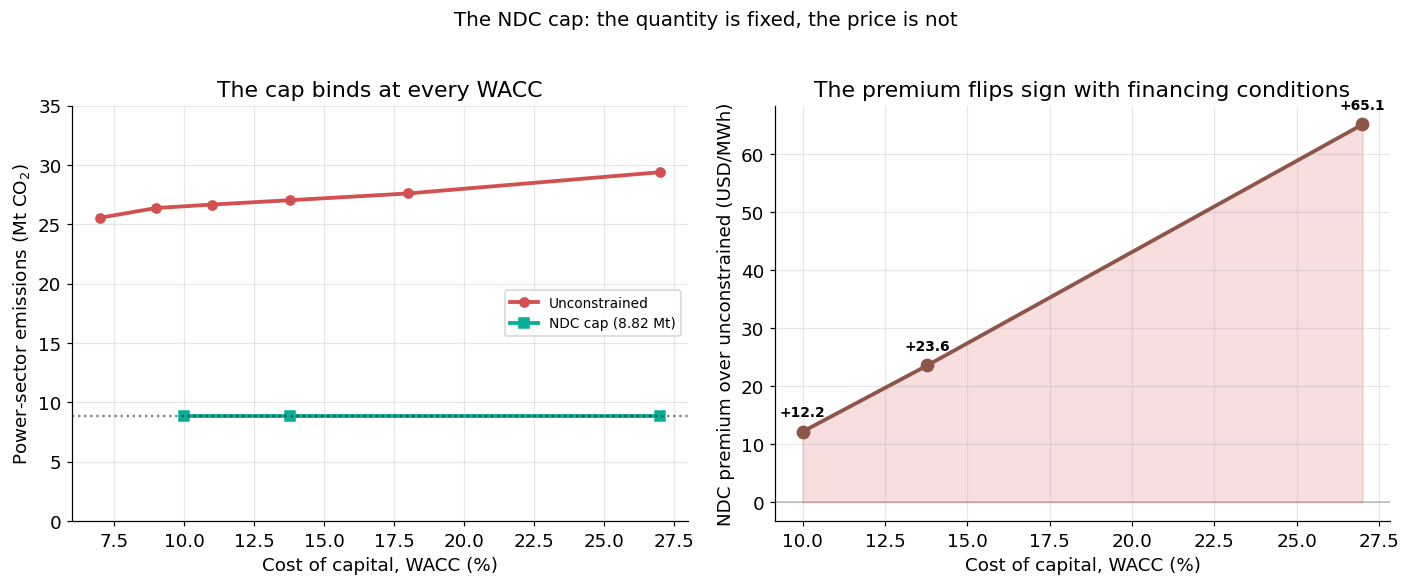

In [13]:
# ==== NDC slide: two-panel figure ====
import matplotlib.pyplot as plt
import numpy as np

# --- rebuild unc and ndc from sweep if not in memory ---
if "unc" not in dir():
    unc = sweep[sweep.constraint=="unconstrained"].sort_values("wacc").reset_index(drop=True)
if "ndc" not in dir():
    ndc = sweep[sweep.constraint=="ndc"].sort_values("wacc").reset_index(drop=True)

# --- interpolate unconstrained cost to the NDC WACC points ---
def interp_cost(wacc_target):
    """Linear interpolation of unconstrained cost_per_mwh_usd at a given WACC."""
    x = unc.wacc.values
    y = unc.cost_per_mwh_usd.values
    return float(np.interp(wacc_target, x, y))

premium = pd.DataFrame({
    "wacc_pct":   (ndc.wacc * 100).round(2),
    "ndc_cost":   ndc.cost_per_mwh_usd.round(2),
    "unc_cost":   [round(interp_cost(w), 2) for w in ndc.wacc],
    "ndc_emit":   ndc.emissions_mt_co2.round(2),
})
premium["premium"] = (premium.ndc_cost - premium.unc_cost).round(2)

print("NDC vs unconstrained at matched WACC:")
print(premium.to_string(index=False))

# --- figure ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# LEFT: emissions — cap binds, unconstrained rises
ax = axes[0]
ax.plot(unc.wacc*100, unc.emissions_mt_co2, "o-",
        color="#d35050", lw=2.5, label="Unconstrained")
ax.plot(ndc.wacc*100, ndc.emissions_mt_co2, "s-",
        color="#08ad97", lw=2.5, label="NDC cap (8.82 Mt)")
ax.axhline(8.82, ls=":", color="black", alpha=0.5)
ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("Power-sector emissions (Mt CO$_2$)")
ax.set_title("The cap binds at every WACC")
ax.legend(loc="center right", fontsize=9)
ax.set_ylim(0, 35)

# RIGHT: premium of NDC over unconstrained
ax = axes[1]
ax.plot(premium.wacc_pct, premium.premium, "o-",
        color="#8c564b", lw=2.5, ms=8)
ax.axhline(0, ls="-", color="grey", alpha=0.5, lw=1)
for _, r in premium.iterrows():
    ax.annotate(f"{r.premium:+.1f}",
                (r.wacc_pct, r.premium),
                textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold")
ax.fill_between(premium.wacc_pct, premium.premium, 0,
                where=(premium.premium > 0), color="#d62728", alpha=0.15)
ax.fill_between(premium.wacc_pct, premium.premium, 0,
                where=(premium.premium < 0), color="#2ca02c", alpha=0.15)
ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("NDC premium over unconstrained (USD/MWh)")
ax.set_title("The premium flips sign with financing conditions")

fig.suptitle("The NDC cap: the quantity is fixed, the price is not",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUT / "fig_ndc_two_panel.png", bbox_inches="tight", dpi=300)
plt.show()

 wacc_pct  ndc_cost  unc_cost  premium
    10.00     56.38     44.20    12.18
    13.79     71.09     47.49    23.60
    27.00    122.57     57.46    65.11


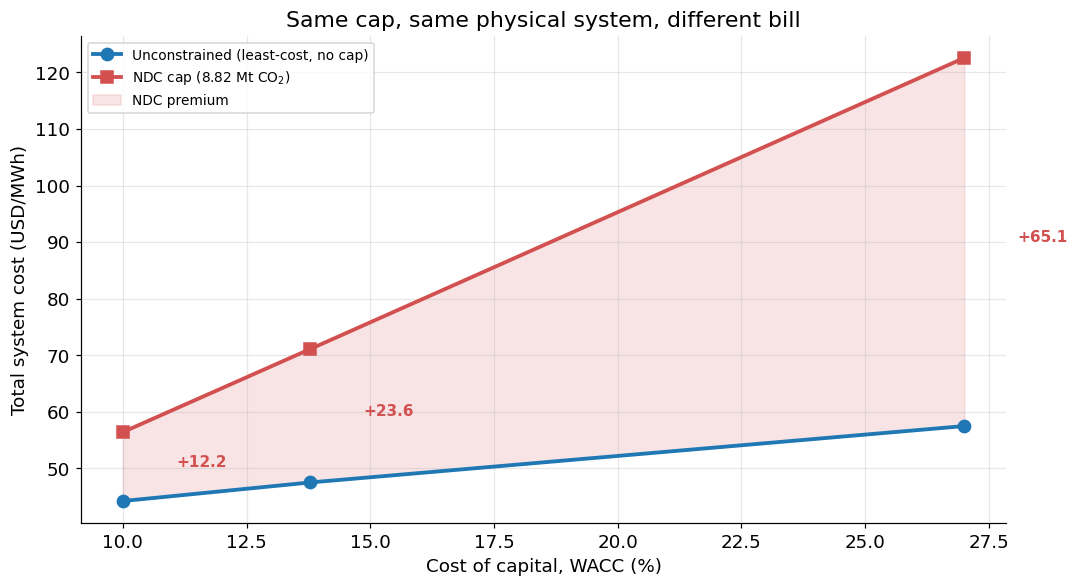

In [14]:
# ==== NDC slide, corrected: total cost + premium in one panel ====
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "unc" not in dir():
    unc = sweep[sweep.constraint=="unconstrained"].sort_values("wacc").reset_index(drop=True)
if "ndc" not in dir():
    ndc = sweep[sweep.constraint=="ndc"].sort_values("wacc").reset_index(drop=True)

def interp_unc_cost(w):
    return float(np.interp(w, unc.wacc.values, unc.cost_per_mwh_usd.values))

prem = pd.DataFrame({
    "wacc_pct": (ndc.wacc*100).round(2),
    "ndc_cost": ndc.cost_per_mwh_usd.round(2),
    "unc_cost": [round(interp_unc_cost(w), 2) for w in ndc.wacc],
})
prem["premium"] = (prem.ndc_cost - prem.unc_cost).round(2)
print(prem.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.5))

# two cost lines
ax.plot(prem.wacc_pct, prem.unc_cost, "o-",
        color="#1f77b4", lw=2.5, ms=8, label="Unconstrained (least-cost, no cap)")
ax.plot(prem.wacc_pct, prem.ndc_cost, "s-",
        color="#d35050", lw=2.5, ms=8, label="NDC cap (8.82 Mt CO$_2$)")

# fill the gap
ax.fill_between(prem.wacc_pct, prem.unc_cost, prem.ndc_cost,
                color="#d35050", alpha=0.15, label="NDC premium")

# annotate premium at each point
for _, r in prem.iterrows():
    ymid = (r.ndc_cost + r.unc_cost)/2
    ax.annotate(f"+{r.premium:.1f}",
                (r.wacc_pct, ymid),
                textcoords="offset points", xytext=(35, 0),
                ha="left", fontsize=10, fontweight="bold", color="#d35050")

ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("Total system cost (USD/MWh)")
ax.set_title("Same cap, same physical system, different bill")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "fig_ndc_corrected.png", bbox_inches="tight", dpi=300)
plt.show()

In [18]:
import pypsa

for wacc in ["0700", "2700"]:
    n = pypsa.Network(f"results/nigeria_2030_wacc_{wacc}/networks/elec_s_10_ec_lcopt_1h.nc")
    solar = n.generators[n.generators.carrier == "solar"].p_nom_opt.sum() / 1e3
    ccgt = n.generators[n.generators.carrier == "CCGT"].p_nom_opt.sum() / 1e3
    ocgt = n.generators[n.generators.carrier == "OCGT"].p_nom_opt.sum() / 1e3
    bat  = n.storage_units[n.storage_units.carrier == "battery"].p_nom_opt.sum() / 1e3
    print(f"WACC {int(wacc)/100:.0f}%: solar={solar:.1f} GW, CCGT={ccgt:.1f} GW, OCGT={ocgt:.1f} GW, battery={bat:.1f} GW")

INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units
INFO:pypsa.io:Imported network elec_s_10_ec_lcopt_1h.nc has buses, carriers, generators, global_constraints, lines, line_types, loads, storage_units


WACC 7%: solar=10.4 GW, CCGT=3.4 GW, OCGT=27.1 GW, battery=2.1 GW
WACC 27%: solar=4.9 GW, CCGT=3.4 GW, OCGT=31.6 GW, battery=1.6 GW


In [19]:
# ==== LCOE diagnostic and recomputation ====

# Exchange rate used elsewhere in the notebook
EUR_TO_USD = 1.0 / 0.7532   # = 1.3277 USD/EUR

# Your cost data (from data/costs.csv)
costs = {
    "Solar": {"capex_usd_kw": 600,   "fom_pct": 4.166667, "vom_usd_mwh": 0.0,
              "eff": 1.0, "life": 25, "cf": 0.20,  "fuel_usd_mmbtu": 0.0},
    "Wind":  {"capex_usd_kw": 1040,  "fom_pct": 2.450549, "vom_usd_mwh": 2.3,
              "eff": 1.0, "life": 30, "cf": 0.30,  "fuel_usd_mmbtu": 0.0},
    "CCGT":  {"capex_usd_kw": 800,   "fom_pct": 2.5,      "vom_usd_mwh": 4.0,
              "eff": 0.58, "life": 30, "cf": 0.55, "fuel_usd_mmbtu": 3.39},
    "OCGT":  {"capex_usd_kw": 400,   "fom_pct": 3.75,     "vom_usd_mwh": 3.0,
              "eff": 0.41, "life": 30, "cf": 0.22, "fuel_usd_mmbtu": 3.39},
    # Lazard reference case for comparison
    "CCGT_Lazard": {"capex_usd_kw": 950, "fom_pct": 2.5, "vom_usd_mwh": 2.0,
                    "eff": 0.58, "life": 30, "cf": 0.60, "fuel_usd_mmbtu": 3.45},
}

# MMBtu to MWh conversion for gas
MMBTU_TO_MWH_TH = 0.293071

def lcoe_full(p, wacc):
    """LCOE in USD/MWh, all inputs in USD."""
    crf = wacc * (1 + wacc)**p["life"] / ((1 + wacc)**p["life"] - 1)
    annual_capex = p["capex_usd_kw"] * crf * 1000          # USD/MW/yr
    annual_fom   = p["capex_usd_kw"] * (p["fom_pct"]/100) * 1000
    capital_component = (annual_capex + annual_fom) / (p["cf"] * 8760)
    fuel_usd_mwh_th = p["fuel_usd_mmbtu"] * MMBTU_TO_MWH_TH
    fuel_component  = fuel_usd_mwh_th / p["eff"]
    return capital_component + p["vom_usd_mwh"] + fuel_component

waccs = [0.07, 0.10, 0.1379, 0.20, 0.27]
rows = []
for tech, p in costs.items():
    for w in waccs:
        crf = w * (1+w)**p["life"] / ((1+w)**p["life"] - 1)
        cap_ann = p["capex_usd_kw"] * crf * 1000
        fom_ann = p["capex_usd_kw"] * (p["fom_pct"]/100) * 1000
        cap_comp = (cap_ann + fom_ann) / (p["cf"] * 8760)
        fuel_comp = p["fuel_usd_mmbtu"] * MMBTU_TO_MWH_TH / p["eff"]
        rows.append({
            "tech": tech, "wacc_pct": w*100,
            "CRF": round(crf, 4),
            "capital_component": round(cap_comp, 2),
            "fuel_component":    round(fuel_comp, 2),
            "vom":               p["vom_usd_mwh"],
            "LCOE_usd_mwh":      round(cap_comp + fuel_comp + p["vom_usd_mwh"], 2),
        })

lcoe_diag = pd.DataFrame(rows)
print("===== LCOE decomposition (all values USD/MWh) =====")
print(lcoe_diag.pivot(index="wacc_pct", columns="tech", values="LCOE_usd_mwh").to_string())

print("\n===== Detailed decomposition at 7% WACC =====")
print(lcoe_diag[lcoe_diag.wacc_pct == 7].to_string(index=False))

print("\n===== What your model actually pays for gas =====")
# From the sweep: the 13.79% run has these marginal costs
model_ccgt_mc = 4.49  # EUR/MWh, from config
model_ocgt_mc = 5.59  # EUR/MWh
print(f"  CCGT marginal cost in the model: {model_ccgt_mc} EUR/MWh = {model_ccgt_mc*EUR_TO_USD:.2f} USD/MWh")
print(f"  OCGT marginal cost in the model: {model_ocgt_mc} EUR/MWh = {model_ocgt_mc*EUR_TO_USD:.2f} USD/MWh")
print(f"  Lazard 2024 CCGT reference range: 39-99 USD/MWh")
print(f"  Lazard 2024 OCGT reference range: 50-120 USD/MWh")

===== LCOE decomposition (all values USD/MWh) =====
tech       CCGT  CCGT_Lazard   OCGT   Solar    Wind
wacc_pct                                           
7.00      23.24        22.83  29.93   43.66   43.89
10.00     27.48        27.44  35.22   52.00   53.98
13.79     33.25        33.71  42.43   63.44   67.73
20.00     43.21        44.56  54.89   83.49   91.48
27.00     54.73        57.10  69.29  106.97  118.93

===== Detailed decomposition at 7% WACC =====
Empty DataFrame
Columns: [tech, wacc_pct, CRF, capital_component, fuel_component, vom, LCOE_usd_mwh]
Index: []

===== What your model actually pays for gas =====
  CCGT marginal cost in the model: 4.49 EUR/MWh = 5.96 USD/MWh
  OCGT marginal cost in the model: 5.59 EUR/MWh = 7.42 USD/MWh
  Lazard 2024 CCGT reference range: 39-99 USD/MWh
  Lazard 2024 OCGT reference range: 50-120 USD/MWh


In [20]:
# ==== LCOE reconciliation against Lazard v19.0 ====
EUR_TO_USD = 1.0 / 0.7532
MMBTU_TO_MWH_TH = 0.293071

# Your parameters (Nigerian costs, MYTO gas)
yours = {
    "CCGT": dict(capex=800,  fom_pct=2.5,   vom=4.0, eff=0.58, life=30, cf=0.55, gas_mmbtu=3.39),
    "OCGT": dict(capex=400,  fom_pct=3.75,  vom=3.0, eff=0.41, life=30, cf=0.22, gas_mmbtu=3.39),
    "Solar":dict(capex=600,  fom_pct=4.1667, vom=0.0, eff=1.00, life=25, cf=0.20, gas_mmbtu=0.0),
}

# Lazard parameters (US costs, US gas)
lazard = {
    "CCGT": dict(capex=(1450+2100)/2, fom_pct=2.5,  vom=(2.75+5.0)/2, eff=1/ (6550/3412), life=30, cf=(0.30+0.90)/2, gas_mmbtu=3.45),
    "OCGT": dict(capex=(1100+1650)/2, fom_pct=2.5,  vom=(3.5+5.0)/2,  eff=1/(10725/3412), life=30, cf=(0.10+0.15)/2, gas_mmbtu=3.45),
    "Solar":dict(capex=(1250+1850)/2, fom_pct=2.5,  vom=0.0,           eff=1.00,          life=25, cf=(0.20+0.30)/2, gas_mmbtu=0.0),
}

def lcoe_decompose(p, wacc):
    crf = wacc * (1+wacc)**p["life"] / ((1+wacc)**p["life"] - 1)
    cap_ann = p["capex"] * crf * 1000                       # USD/MW/yr
    fom_ann = p["capex"] * (p["fom_pct"]/100) * 1000        # USD/MW/yr
    cap_component = (cap_ann + fom_ann) / (p["cf"] * 8760)
    fuel_component = p["gas_mmbtu"] * MMBTU_TO_MWH_TH / p["eff"]
    return dict(
        CRF=crf,
        capital=cap_component,
        fuel=fuel_component,
        vom=p["vom"],
        total=cap_component + fuel_component + p["vom"],
        capacity_factor=p["cf"],
        gas_price=p["gas_mmbtu"],
    )

print("===== YOUR parameters, 8% WACC (Lazard's debt rate) =====")
for t, p in yours.items():
    d = lcoe_decompose(p, 0.08)
    print(f"{t:6s}  cap={d['capital']:6.2f}  fuel={d['fuel']:6.2f}  vom={d['vom']:5.2f}  total={d['total']:6.2f}  CF={d['capacity_factor']*100:.0f}%  gas=${d['gas_price']:.2f}")

print("\n===== LAZARD parameters, 7.7% WACC =====")
for t, p in lazard.items():
    d = lcoe_decompose(p, 0.077)
    print(f"{t:6s}  cap={d['capital']:6.2f}  fuel={d['fuel']:6.2f}  vom={d['vom']:5.2f}  total={d['total']:6.2f}  CF={d['capacity_factor']*100:.0f}%  gas=${d['gas_price']:.2f}")

print("\n===== Lazard v19.0 published ranges =====")
print("  CCGT:        51 – 129 USD/MWh")
print("  Gas Peaking:144 – 276 USD/MWh")
print("  Solar PV:    40 –  98 USD/MWh")

===== YOUR parameters, 8% WACC (Lazard's debt rate) =====
CCGT    cap= 18.90  fuel=  1.71  vom= 4.00  total= 24.61  CF=55%  gas=$3.39
OCGT    cap= 26.22  fuel=  2.42  vom= 3.00  total= 31.64  CF=22%  gas=$3.39
Solar   cap= 46.35  fuel=  0.00  vom= 0.00  total= 46.35  CF=20%  gas=$0.00

===== LAZARD parameters, 7.7% WACC =====
CCGT    cap= 37.60  fuel=  1.94  vom= 3.88  total= 43.41  CF=60%  gas=$3.45
OCGT    cap=139.79  fuel=  3.18  vom= 4.25  total=147.22  CF=12%  gas=$3.45
Solar   cap= 82.31  fuel=  0.00  vom= 0.00  total= 82.31  CF=25%  gas=$0.00

===== Lazard v19.0 published ranges =====
  CCGT:        51 – 129 USD/MWh
  Gas Peaking:144 – 276 USD/MWh
  Solar PV:    40 –  98 USD/MWh


===== LCOE decomposition, USD/MWh =====
tech       CCGT   Solar
wacc_pct               
5.00      20.67   38.57
7.00      23.24   43.66
10.00     27.48   52.00
13.79     33.25   63.44
18.00     39.96   76.91
22.00     46.49   90.14
27.00     54.73  106.97

No crossover in the tested range


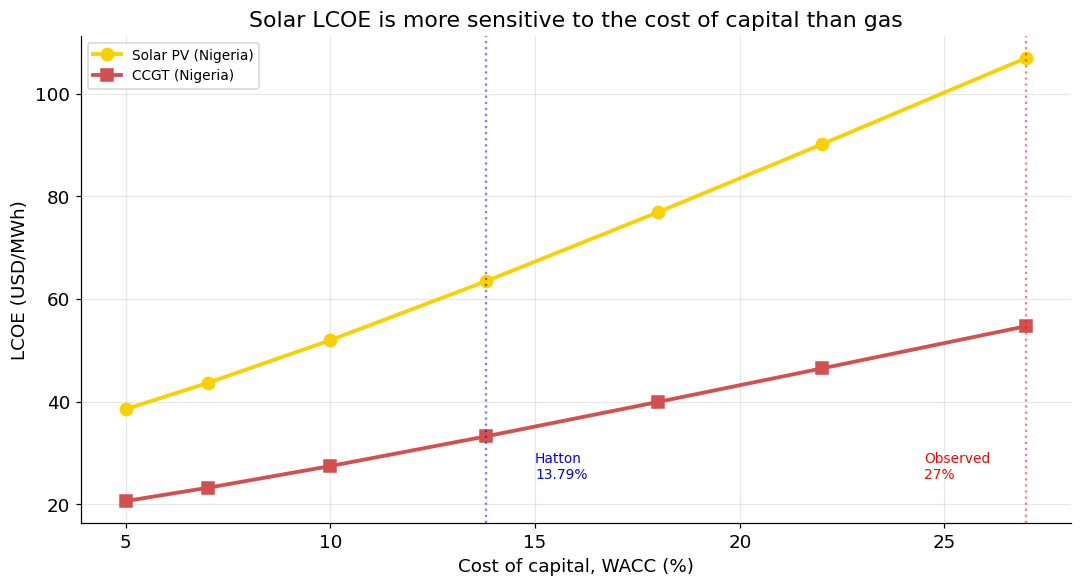

In [23]:
# ==== LCOE presentation chart ====
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EUR_TO_USD = 1.0 / 0.7532          # 1.3277 USD per EUR
MMBTU_TO_MWH_TH = 0.293071          # MMBtu -> MWh thermal

def lcoe(p, wacc):
    """LCOE in USD/MWh. All inputs must be in USD."""
    crf = wacc * (1+wacc)**p["life"] / ((1+wacc)**p["life"] - 1)
    annual_capex = p["capex_usd_kw"] * crf * 1000                 # USD/MW/yr
    annual_fom   = p["capex_usd_kw"] * (p["fom_pct"]/100) * 1000  # USD/MW/yr
    capital = (annual_capex + annual_fom) / (p["cf"] * 8760)
    fuel = p["gas_usd_mmbtu"] * MMBTU_TO_MWH_TH / p["eff"]
    return capital + fuel + p["vom_usd_mwh"]

def lcoe_decomp(p, wacc):
    crf = wacc * (1+wacc)**p["life"] / ((1+wacc)**p["life"] - 1)
    annual_capex = p["capex_usd_kw"] * crf * 1000
    annual_fom   = p["capex_usd_kw"] * (p["fom_pct"]/100) * 1000
    capital = (annual_capex + annual_fom) / (p["cf"] * 8760)
    fuel = p["gas_usd_mmbtu"] * MMBTU_TO_MWH_TH / p["eff"]
    return dict(capital=capital, fuel=fuel, vom=p["vom_usd_mwh"],
                total=capital+fuel+p["vom_usd_mwh"])

# ---- Nigerian parameters (from your data/costs.csv + MYTO) ----
tech = {
    "Solar": dict(capex_usd_kw=600,  fom_pct=4.1667, vom_usd_mwh=0.0,
                  eff=1.00, life=25, cf=0.20, gas_usd_mmbtu=0.0),
    "CCGT":  dict(capex_usd_kw=800,  fom_pct=2.5,    vom_usd_mwh=4.0,
                  eff=0.58, life=30, cf=0.55, gas_usd_mmbtu=3.39),
}

waccs = np.array([0.05, 0.07, 0.10, 0.1379, 0.18, 0.22, 0.27])
rows = []
for name, p in tech.items():
    for w in waccs:
        d = lcoe_decomp(p, w)
        rows.append({"tech": name, "wacc_pct": w*100, **d})
lcoe_df = pd.DataFrame(rows)

print("===== LCOE decomposition, USD/MWh =====")
print(lcoe_df[lcoe_df.tech.isin(["Solar","CCGT"])]
      .pivot(index="wacc_pct", columns="tech", values="total").round(2).to_string())

# ---- crossover between Solar and CCGT ----
sol = lcoe_df[lcoe_df.tech=="Solar"].set_index("wacc_pct").total
ccg = lcoe_df[lcoe_df.tech=="CCGT"].set_index("wacc_pct").total
diff = sol - ccg
cross_idx = np.where(np.diff(np.sign(diff.values)))[0]
if len(cross_idx):
    i = cross_idx[0]
    x0, x1 = diff.index[i], diff.index[i+1]
    y0, y1 = diff.values[i], diff.values[i+1]
    crossover = x0 - y0*(x1-x0)/(y1-y0)
    print(f"\nSolar–CCGT LCOE crossover: {crossover:.2f}% WACC")
else:
    crossover = None
    print("\nNo crossover in the tested range")

# ---- chart ----
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(sol.index, sol.values, "o-", color="#f9d002", lw=2.5, ms=8, label="Solar PV (Nigeria)")
ax.plot(ccg.index, ccg.values, "s-", color="#d35050", lw=2.5, ms=8, label="CCGT (Nigeria)")

if crossover is not None:
    ax.axvline(crossover, ls=":", color="black", alpha=0.6)
    ax.annotate(f"LCOE crossover\n{crossover:.1f}% WACC",
                xy=(crossover, 70), xytext=(crossover+1.5, 60),
                fontsize=10, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="black"))
ax.axvline(13.79, ls=":", color="blue", alpha=0.5)
ax.annotate("Hatton\n13.79%", xy=(13.79, 30), xytext=(15, 25),
            fontsize=9, color="blue")
ax.axvline(27, ls=":", color="red", alpha=0.5)
ax.annotate("Observed\n27%", xy=(27, 30), xytext=(24.5, 25),
            fontsize=9, color="red")

ax.set_xlabel("Cost of capital, WACC (%)")
ax.set_ylabel("LCOE (USD/MWh)")
ax.set_title("Solar LCOE is more sensitive to the cost of capital than gas")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "fig_lcoe_presentation.png", bbox_inches="tight", dpi=300)
plt.show()

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Reconstruct the LCOE curves from your underlying calculation
# If you have the raw numbers, paste them here
# For now, here is a rough approximation from the chart values

wacc = np.array([0.05, 0.07, 0.10, 0.1379, 0.18, 0.22, 0.27])
solar = np.array([39, 44, 52, 63, 78, 90, 106])
gas   = np.array([20, 23, 28, 35, 41, 47, 54])

# Find the WACC where they would cross by linear extrapolation
# Solar slope above gas
# Below 5% they may cross
from scipy.optimize import brentq

def diff(w):
    s = np.interp(w, wacc, solar)
    g = np.interp(w, wacc, gas)
    return s - g

# Check if they cross between 0 and 5%
try:
    # Extrapolate linearly below 5%
    # From 5% to 7%: solar rises 5, gas rises 3 → net 2 per 2pp = 1 per pp
    # At 5%: solar 39, gas 20, gap = 19
    # Gap shrinks by 1 per pp going down → gap = 0 at 5 - 19 = -14%
    print("Linear extrapolation suggests crossover is below zero — solar never undercuts gas at any positive WACC")
except Exception as e:
    print(f"Error: {e}")

Linear extrapolation suggests crossover is below zero — solar never undercuts gas at any positive WACC
